# [GSE196084](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE196084)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2022-11-04
> - Modified: 2025-02-23

# 1. Experimental Design

> Transcriptomic Analysis of Naïve mESC, Primed mESC and EpiLC.
> - Galle, E., Wong, CW., Ghosh, A. et al. H3K18 lactylation marks tissue-specific active enhancers. Genome Biol 23, 207 (2022). https://doi.org/10.1186/s13059-022-02775-y.
> - poly(A) RNA-seq
> - Illumina Novaseq, PE50
> - mm10

| Sample | Organism | Strand | Cell | Source | Genotype | Stage | Treatment | Replicate |
| - | - | - | - | - | - | - | - | - |
| Naive | Mus musculus | 129/Ola | mESC | Embryonic stem cells | WT | Naive | 2i LIF | rep1~3 |
| Primed | Mus musculus | 129/Ola | mESC | Embryonic stem cells | WT | Primed | serum LIF | rep1~3 |
| EpiLC | Mus musculus | 129/Ola | mESC | Embryonic stem cells | WT | EpiLC | differentiated | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Diff_GSE196084"

In [3]:
stage_levels <- c("Naive", "Primed", "EpiLC")

In [4]:
raw_counts <- file.path(data_dir, "GSE196084_E14_rawCounts.txt") |>
    read.table(row.names = 1, header = TRUE, sep = "\t") |>
    as.matrix()

dim(raw_counts)
head(raw_counts)

[1] 38293     9

,E14_Naive_rep1,E14_Naive_rep2,E14_Naive_rep3,E14_EpiLC_rep1,E14_EpiLC_rep2,E14_EpiLC_rep3,E14_Primed_rep1,E14_Primed_rep2,E14_Primed_rep3
ENSMUSG00000094121,0,0,0,0,0,0,0,0,0
ENSMUSG00000094576,0,0,0,0,0,0,0,0,0
ENSMUSG00000079764,0,0,0,0,0,0,0,0,0
ENSMUSG00000093972,0,0,0,0,0,0,0,0,0
ENSMUSG00000096416,0,0,0,0,0,0,0,0,0
ENSMUSG00000079774,0,0,0,0,0,0,0,0,0


In [5]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    separate(
        col = sample, into = c("Cell", "Stage", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample),
        Stage = factor(Stage, levels = stage_levels), 
        Replicate = factor(Replicate)) |> 
    arrange(Stage, Replicate) |> 
    column_to_rownames("sample")

coldata

,Cell,Stage,Replicate
,<chr>,<fct>,<fct>
Naive_rep1,E14,Naive,rep1
Naive_rep2,E14,Naive,rep2
Naive_rep3,E14,Naive,rep3
Primed_rep1,E14,Primed,rep1
Primed_rep2,E14,Primed,rep2
Primed_rep3,E14,Primed,rep3
EpiLC_rep1,E14,EpiLC,rep1
EpiLC_rep2,E14,EpiLC,rep2
EpiLC_rep3,E14,EpiLC,rep3


In [6]:
gtf <- file.path("~/reference/Mus_musculus/mm10", "gencode.vM23.annotation.gtf") |>
    rtracklayer::import()

In [7]:
Sys.time()
exons_length <- gtf |> 
    subset(type == "exon") |>
    split(~ gene_id) |>
    lapply(reduce) |>
    sapply(FUN = function(gr) sum(width(gr))) |>
    enframe(name = "gene_id", value = "basepairs")
Sys.time()

[1] "2026-06-22 14:45:16 CST"

[1] "2026-06-22 14:50:15 CST"

In [8]:
anno_gene <- gtf |>
    subset(type == "gene") |>
    subset(gene_type %in% c("protein_coding", "lncRNA")) |>
    as.data.frame() |>
    distinct(
        chr = seqnames, start, end, strand, 
        gene_id, symbol = gene_name, type = gene_type) |>
    left_join(exons_length, by = "gene_id") |>
    mutate(gene_id = sub("\\..*$", "", gene_id)) |>
    column_to_rownames("gene_id") |> 
    GRanges()

anno_gene

GRanges object with 31812 ranges and 3 metadata columns:
                     seqnames          ranges strand |      symbol
                        <Rle>       <IRanges>  <Rle> | <character>
  ENSMUSG00000051951     chr1 3205901-3671498      - |        Xkr4
  ENSMUSG00000089699     chr1 3466587-3513553      + |      Gm1992
  ENSMUSG00000102331     chr1 3647309-3658904      - |     Gm19938
  ENSMUSG00000102343     chr1 3905739-3986215      - |     Gm37381
  ENSMUSG00000025900     chr1 3999557-4409241      - |         Rp1
                 ...      ...             ...    ... .         ...
  ENSMUSG00000065947     chrM      9877-10173      + |     mt-Nd4l
  ENSMUSG00000064363     chrM     10167-11544      + |      mt-Nd4
  ENSMUSG00000064367     chrM     11742-13565      + |      mt-Nd5
  ENSMUSG00000064368     chrM     13552-14070      - |      mt-Nd6
  ENSMUSG00000064370     chrM     14145-15288      + |     mt-Cytb
                               type basepairs
                        <c

## 2). Object Construction

In [9]:
common_genes <- intersect(rownames(raw_counts), names(anno_gene))

In [10]:
length(rownames(raw_counts))
length(names(anno_gene))
length(common_genes)

[1] 38293

[1] 31812

[1] 24855

In [11]:
raw_counts <- raw_counts |> 
    (\(x) { colnames(x) <- sub("^[^_]+_", "", colnames(x)); x })() |>
    (\(x) x[common_genes, rownames(coldata)])()

dim(raw_counts)

[1] 24855     9

In [12]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowRanges = anno_gene[common_genes, ], 
    colData = coldata)

eSet

class: RangedSummarizedExperiment 
dim: 24855 9 
metadata(0):
assays(1): counts
rownames(24855): ENSMUSG00000096426 ENSMUSG00000094558 ...
  ENSMUSG00000064368 ENSMUSG00000064370
rowData names(3): symbol type basepairs
colnames(9): Naive_rep1 Naive_rep2 ... EpiLC_rep2 EpiLC_rep3
colData names(3): Cell Stage Replicate

In [13]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, 
    rowRanges = anno_gene[common_genes, ], 
    colData = coldata, 
    design = ~ 0 + Stage)
dds

class: DESeqDataSet 
dim: 24855 9 
metadata(1): version
assays(1): counts
rownames(24855): ENSMUSG00000096426 ENSMUSG00000094558 ...
  ENSMUSG00000064368 ENSMUSG00000064370
rowData names(3): symbol type basepairs
colnames(9): Naive_rep1 Naive_rep2 ... EpiLC_rep2 EpiLC_rep3
colData names(3): Cell Stage Replicate

In [14]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene[common_genes, ], 
    samples = coldata, group = coldata$Stage)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [15]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 14035 
 Remove: 10820 
 Retention rate: 56.47 %


In [16]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 13971 
 Remove: 10884 
 Retention rate: 56.21 %


# 3. Normalization

In [17]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [18]:
dds <- estimateSizeFactors(dds)
norm_fpkm <- fpkm(dds, robust = TRUE)

In [19]:
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [20]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [21]:
rld <- rlog(dds, blind = FALSE)

In [22]:
suppressPackageStartupMessages(library(vsn))

In [23]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [24]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


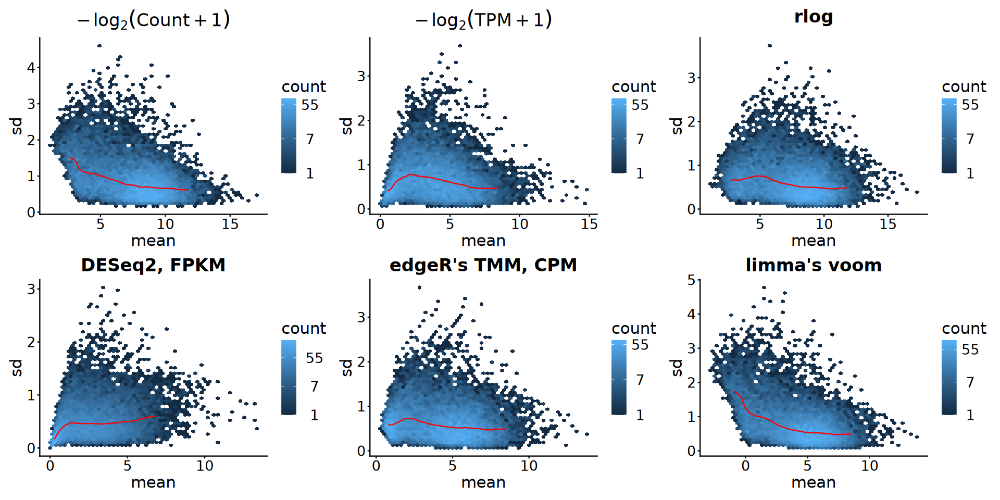

In [25]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [26]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [27]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Stage, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

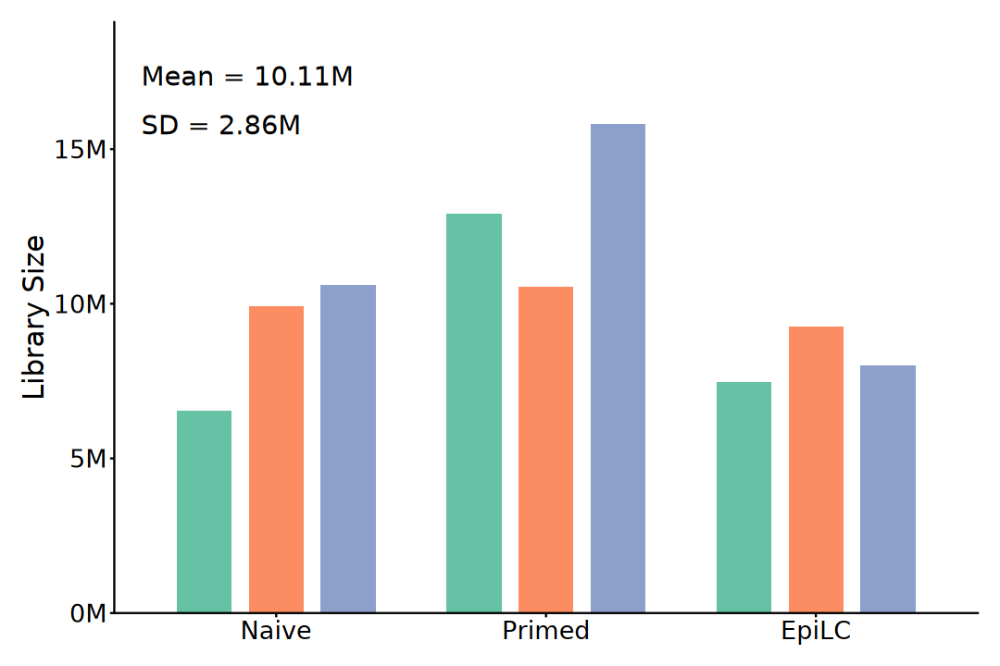

In [28]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Stage, y = librarySize)) +
    geom_col(
        aes(fill = Replicate, group = Sample), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, show.legend = FALSE) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6, 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.0,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6, 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [29]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [30]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [31]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Stage, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [32]:
pca_res <- plotPCA(
    rld, intgroup = c("Stage", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [33]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Stage, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [34]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
set.seed(123)

gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [35]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Stage, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)),
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

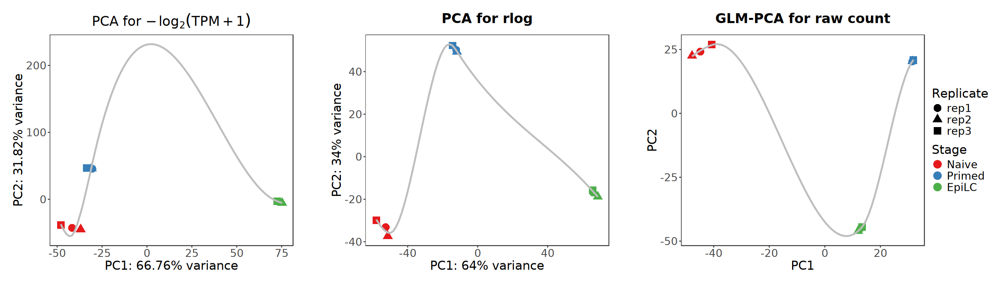

In [36]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [37]:
dist_mat <- norm_mat[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

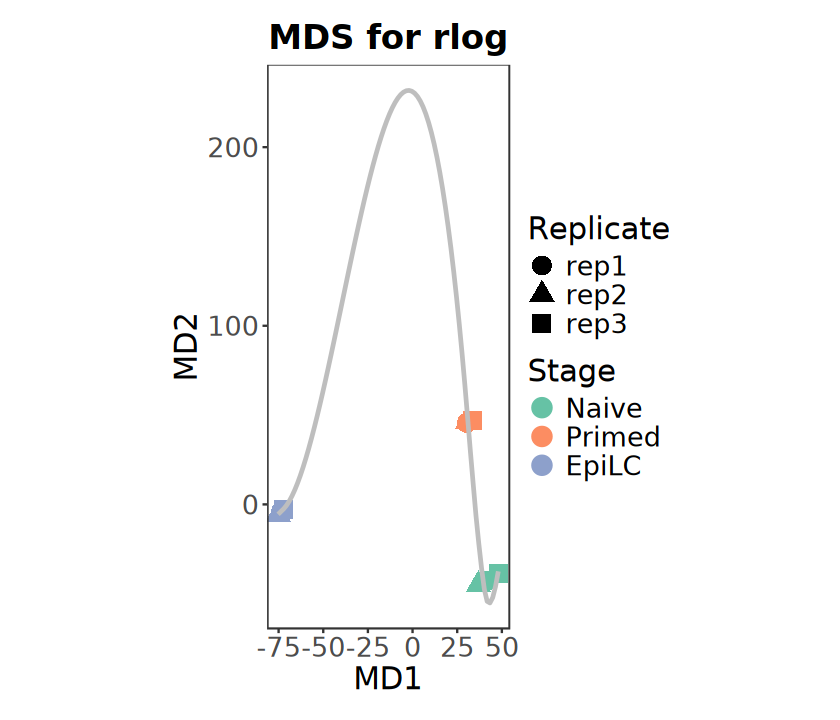

In [38]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Stage, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    # geom_path(
    #     aes(group = 1), color = "black", 
    #     arrow = arrow(length = unit(0.15, "inches"))) +
    scale_color_brewer(palette = "Set2") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [39]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

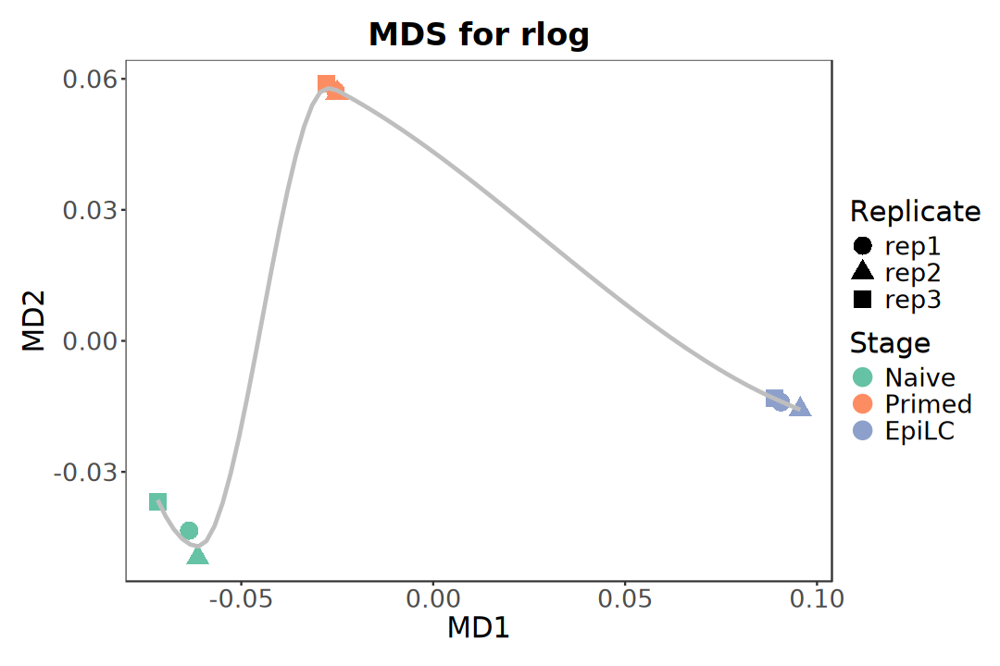

In [40]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Stage, shape = Replicate), size = 5) +
    geom_smooth(
        formula = "y ~ x", method = "loess", se = FALSE,
        color = "grey", linewidth = 1) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Correlation

In [41]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Stage)

In [42]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Stage)),
    levels(eSet$Stage))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Stage = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [43]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

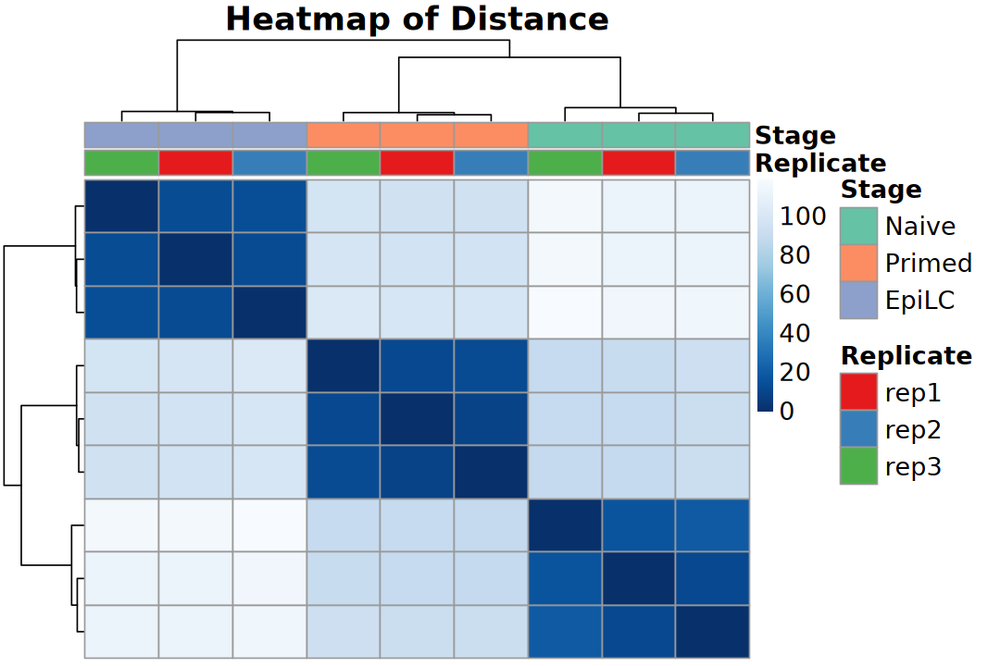

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [45]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

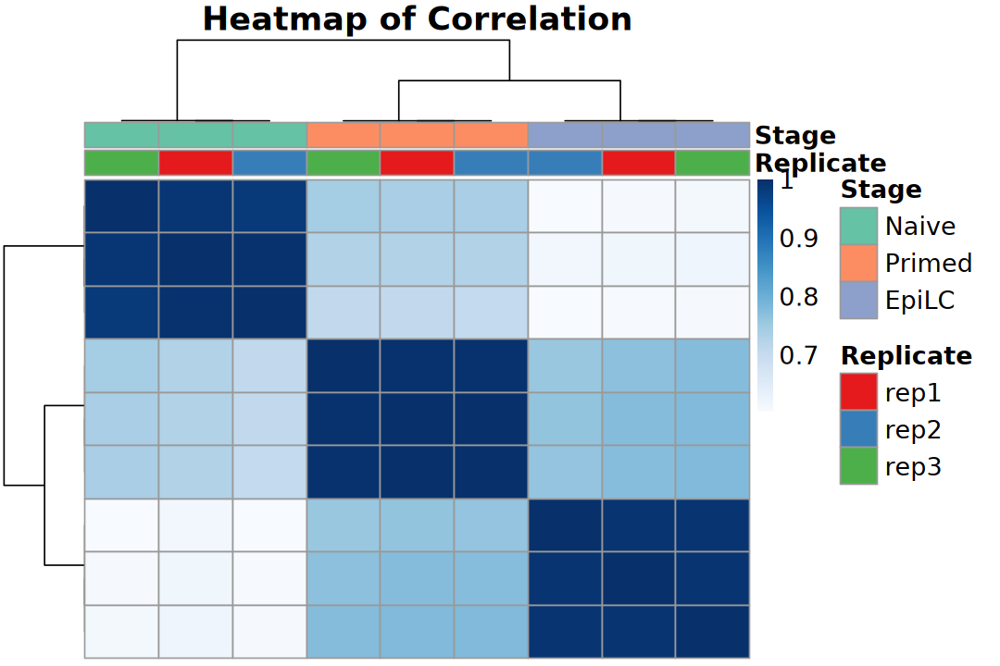

In [46]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

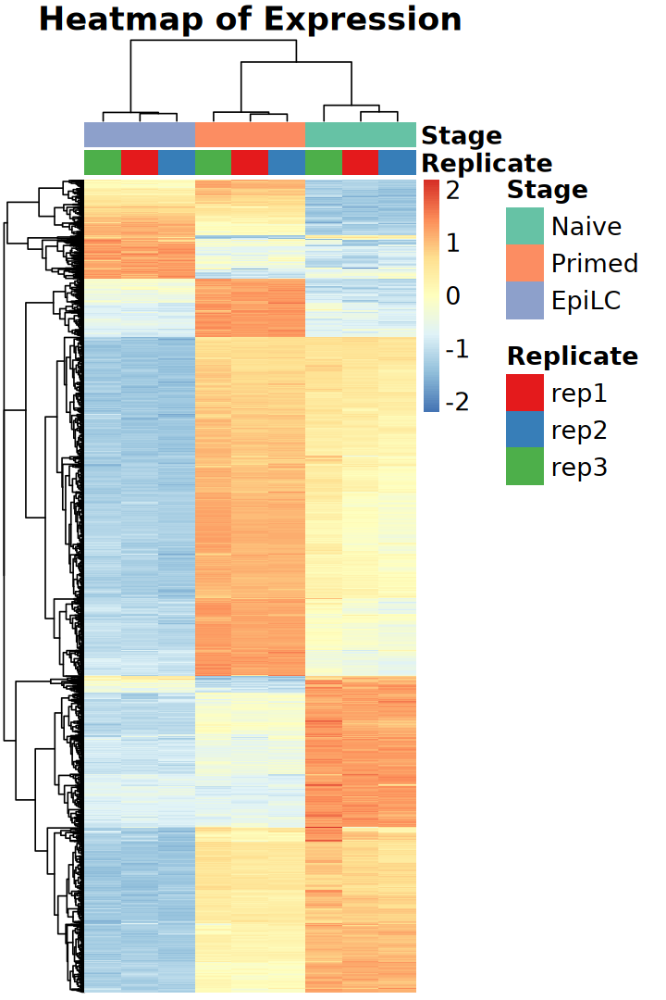

In [47]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs: Pairwise

> Sequential pairwise contrast is a differential expression analysis strategy that compares consecutive time points or developmental stages to identify stage-specific transcriptional dynamics. The primary advantage of this localized approach lies in its ability to capture temporal gene expression trajectories and pinpoint critical transition windows with high chronological resolution. However, this sequential strategy inevitably escalates the multiple-testing burden and may overlook cumulative expression changes spanning distant stages. Consequently, it is frequently complemented by global or longitudinal analytical frameworks to achieve a holistic view of the transcriptomic landscape.

In [48]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.05

## a). DESeq2

> median of ratios for normalization

In [49]:
design(dds) <- ~ 0 + Stage
design(dds)

~0 + Stage

In [50]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [51]:
resultsNames(dds)

[1] "StageNaive"  "StagePrimed" "StageEpiLC"

In [52]:
contrast_pairs <- levels(dds$Stage) |>
    combn(2, simplify = FALSE)
contrast_pairs

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

[[1]]
[1] "Naive"  "Primed"

[[2]]
[1] "Naive" "EpiLC"

[[3]]
[1] "Primed" "EpiLC"

[1] "Primed_vs_Naive" "EpiLC_vs_Naive"  "EpiLC_vs_Primed"

In [53]:
deseq2_result_list <- map(contrast_pairs, function(lv) {
    results(dds, contrast = c("Stage", lv[2], lv[1])) |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2",
            contrast = paste0(lv[2], "_vs_", lv[1]),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

In [54]:
deseq2_result_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_result_df$contrast, deseq2_result_df$result)

                 
                     Up  Down    NS
  Primed_vs_Naive   752   942 12341
  EpiLC_vs_Naive   1095  1661 11279
  EpiLC_vs_Primed  1156  1452 11427

## b). edgeR

> Trimmed Mean of M-values (TMM)
> 
> Quasi-likelihood pipeline

In [55]:
design <- model.matrix(~ 0 + group, data = dgel$samples)
colnames(design) <- levels(dgel$samples$group)
design

,Naive,Primed,EpiLC
Naive_rep1,1,0,0
Naive_rep2,1,0,0
Naive_rep3,1,0,0
Primed_rep1,0,1,0
Primed_rep2,0,1,0
Primed_rep3,0,1,0
EpiLC_rep1,0,0,1
EpiLC_rep2,0,0,1
EpiLC_rep3,0,0,1


In [56]:
contrast_pairs <- levels(dgel$samples$group) |>
    combn(2, simplify = FALSE)
contrast_pairs

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

contrast_matrix <- contrast_pairs |> 
    map(function(lv) {paste0(lv[2], "-", lv[1])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_matrix

[[1]]
[1] "Naive"  "Primed"

[[2]]
[1] "Naive" "EpiLC"

[[3]]
[1] "Primed" "EpiLC"

[1] "Primed_vs_Naive" "EpiLC_vs_Naive"  "EpiLC_vs_Primed"

,Primed-Naive,EpiLC-Naive,EpiLC-Primed
Naive,-1,-1,0
Primed,1,0,-1
EpiLC,0,1,1


In [57]:
dgel <- estimateDisp(dgel, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)

In [ ]:
edger_qlf_result_list <- map(colnames(contrast_matrix), function(idx) {
    glmQLFTest(fit, contrast = contrast_matrix[, idx]) |>
        topTags(n = Inf) |> as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            method = "edgeR",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [59]:
edger_qlf_result_df <- bind_rows(edger_qlf_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(edger_qlf_result_df$contrast, edger_qlf_result_df$result)

                 
                     Up  Down    NS
  Primed_vs_Naive   730   961 12280
  EpiLC_vs_Naive   1010  1751 11210
  EpiLC_vs_Primed  1078  1503 11390

## c). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [60]:
design <- model.matrix(~ 0 + group, data = dgel$samples)
colnames(design) <- levels(dgel$samples$group)

In [61]:
contrast_pairs <- levels(dgel$samples$group) |>
    combn(2, simplify = FALSE)
contrast_pairs

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

contrast_matrix <- contrast_pairs |> 
    map(function(lv) {paste0(lv[2], "-", lv[1])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_matrix

[[1]]
[1] "Naive"  "Primed"

[[2]]
[1] "Naive" "EpiLC"

[[3]]
[1] "Primed" "EpiLC"

[1] "Primed_vs_Naive" "EpiLC_vs_Naive"  "EpiLC_vs_Primed"

,Primed-Naive,EpiLC-Naive,EpiLC-Primed
Naive,-1,-1,0
Primed,1,0,-1
EpiLC,0,1,1


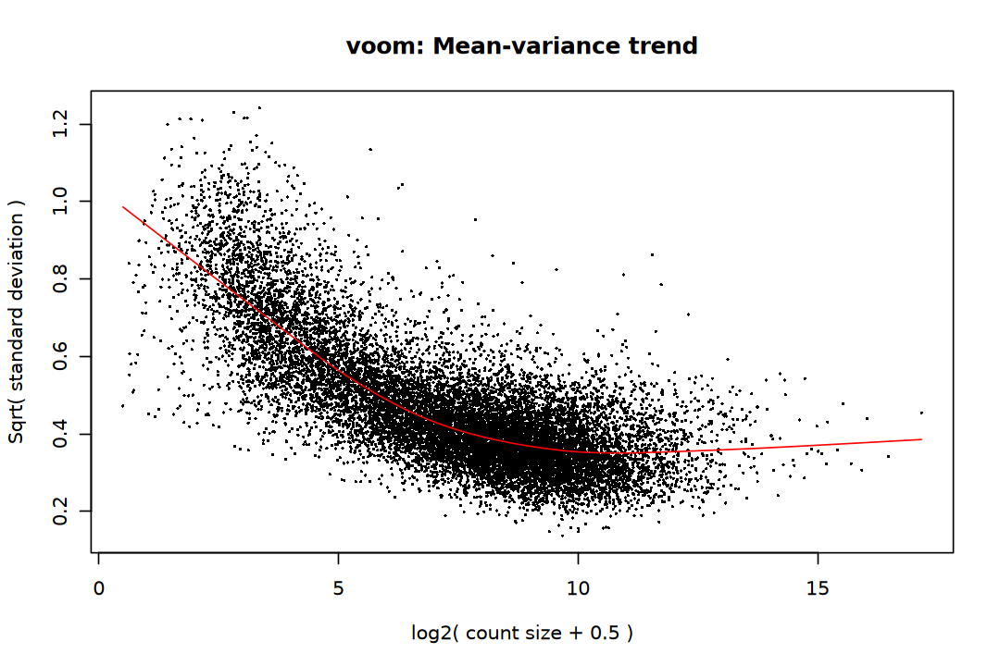

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [63]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Compute contrasts from linear model fit
fit <- contrasts.fit(fit, contrast_matrix)
# Empirical Bayes Statistics for Differential Expression
fit <- eBayes(fit)

In [64]:
limma_result_list <- map(colnames(contrast_matrix), function(idx) {
    topTable(fit, coef = idx, number = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
        mutate(
            method = "limma",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [65]:
limma_result_df <- bind_rows(limma_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(limma_result_df$contrast, limma_result_df$result)

                 
                     Up  Down    NS
  Primed_vs_Naive   738   955 12278
  EpiLC_vs_Naive   1037  1711 11223
  EpiLC_vs_Primed  1088  1478 11405

## DEGs Evaluation

In [66]:
all_results <- bind_rows(
    deseq2_result_df, edger_qlf_result_df, limma_result_df)

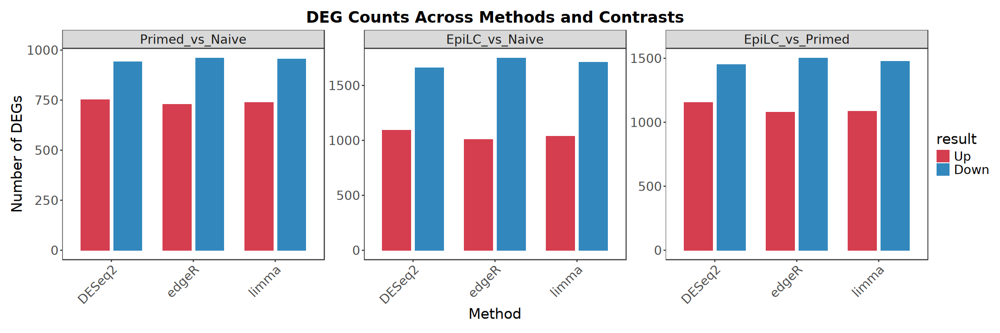

In [67]:
options(repr.plot.width = 18, repr.plot.height = 6)

all_results |> filter(result != "NS") |> 
    dplyr::count(method, contrast, result) |>
    ggplot(aes(x = method, y = n, fill = result)) +
        geom_col(position = position_dodge(width = 0.8), width = 0.7) +
        facet_wrap(~ contrast, nrow = 1, scales = "free_y") +
        scale_fill_manual(
            values = c("Up" = "#D53E4F", "Down" = "#3288BD")) +
        labs(
            title = "DEG Counts Across Methods and Contrasts", 
            x = "Method", y = "Number of DEGs") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            strip.text = element_text(size = 16),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
            axis.text.y = element_text(size = 16))

In [68]:
# ------------------------------------------------------------------------------
# Function: summarize_software_deg_overlaps
#
# Description:
# This function computes and summarizes the overlap composition of DEG sets 
# across different software packages (e.g., DESeq2, edgeR, limma) within a contrast.
# ------------------------------------------------------------------------------
summarize_software_deg_overlaps <- function(prefix, deg_list) {
    sample_names <- grep(
        paste0("^", prefix, "_"), names(deg_list), value = TRUE)
    software_id <- str_replace_all(
        sample_names, paste0(prefix, "_"), "")
    
    comb_levels <- unlist(lapply(seq_along(software_id), function(i) {
        combn(software_id, i, FUN = function(x) 
            paste(x, collapse = "&"), simplify = TRUE)
    }), use.names = FALSE)
    
    current_list <- deg_list[sample_names]
    names(current_list) <- software_id
    
    all_genes <- unique(unlist(current_list))
    
    venn_grid <- expand.grid(rep(list(c(0, 1)), length(software_id))) |> 
        set_names(software_id)
    
    counts_df <- map_dfc(current_list, ~ as.integer(all_genes %in% .x)) |> 
        group_by(across(all_of(software_id))) |> 
        summarise(Counts = n(), .groups = "drop")
    
    venn_grid |> left_join(counts_df, by = software_id) |> 
        mutate(Counts = replace_na(Counts, 0)) |> rowwise() |> 
        mutate(
            Combination = {
                vals <- c_across(all_of(software_id))
                present <- software_id[vals == 1]
                if (length(present) == 0) "none" else 
                paste(present, collapse = "&")
            } |> factor(levels = comb_levels), 
            Group = prefix) |> 
        ungroup() |> 
        filter(Combination != "none") |> 
        dplyr::select(Group, Combination, Counts) |> 
        as.data.frame()
}

In [69]:
deg_list <- all_results |> filter(result != "NS") |> 
    mutate(list_name = paste0(contrast, "_", method)) |> 
    group_by(list_name) |> 
    summarise(genes = list(gene_id)) |> 
    deframe()

deg_overlap_df <- map(contrast_labels, function(con) {
    summarize_software_deg_overlaps(prefix = con, deg_list = deg_list)}) |> 
    list_rbind()

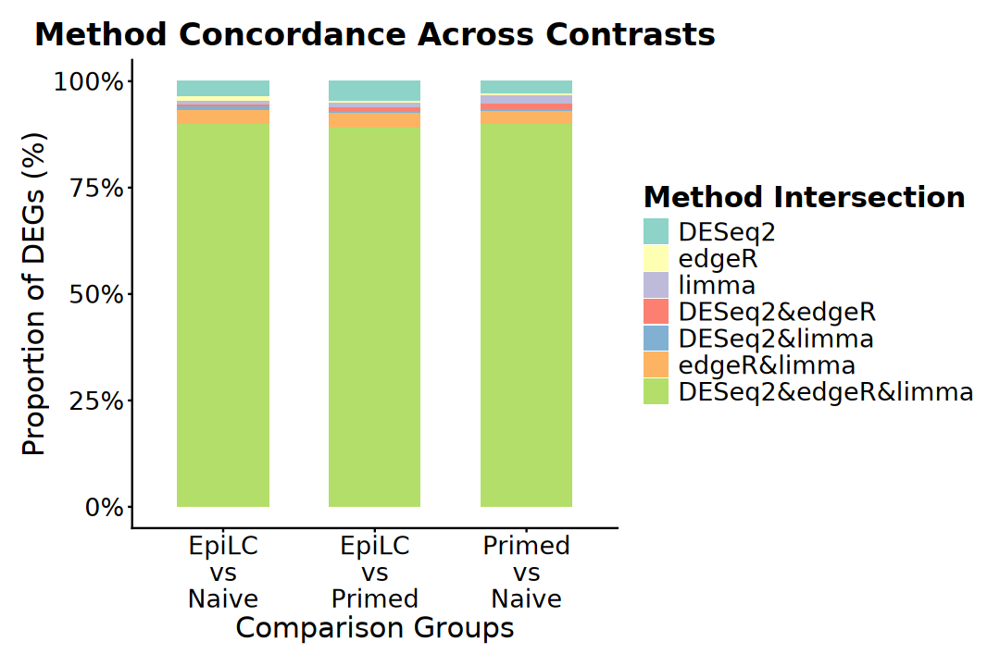

In [70]:
options(repr.plot.width = 9, repr.plot.height = 6)

deg_overlap_df |>
    mutate(Group = str_replace_all(Group, "_", "\n")) |>
    ggplot(aes(x = Group, y = Counts, fill = Combination)) +
        geom_bar(stat = "identity", position = "fill", width = 0.6) +
        scale_y_continuous(labels = scales::percent_format()) + 
        scale_fill_brewer(palette = "Set3") +
        labs(
            title = "Method Concordance Across Contrasts",
            x = "Comparison Groups", 
            y = "Proportion of DEGs (%)",
            fill = "Method Intersection"
        ) +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"), 
            legend.position = "right", 
            legend.title = element_text(size = 18, face = "bold"), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

## DEGs Visualization

In [71]:
contrast_labels

[1] "Primed_vs_Naive" "EpiLC_vs_Naive"  "EpiLC_vs_Primed"

### Multi-group Volcano

In [72]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

                 
                     Up  Down    NS
  Primed_vs_Naive   752   942 12341
  EpiLC_vs_Naive   1095  1661 11279
  EpiLC_vs_Primed  1156  1452 11427

In [73]:
max_logfc <- deg_df$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- deg_df$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

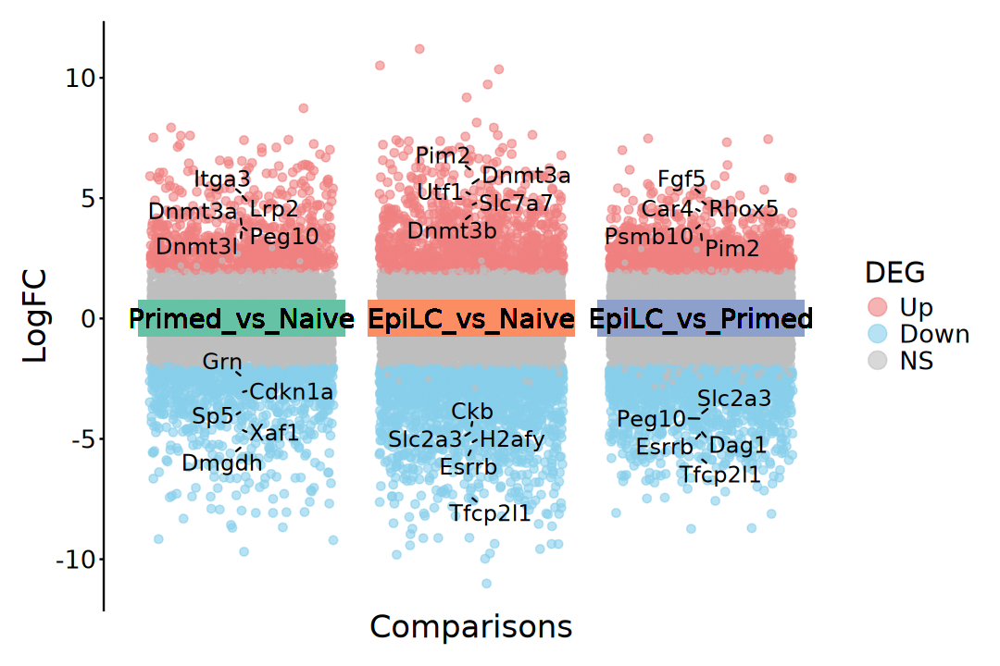

In [74]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deg_df, aes(x = contrast, y = logFC)) + 
    geom_point(
        aes(color = result, size = result), 
        position = position_jitter(width = 0.4, height = 0), 
        na.rm = TRUE, alpha = 0.6) +
    geom_tile(
        aes(x = contrast, y = 0, fill = contrast), 
        width = 0.9, height = 1.5, show.legend = FALSE) +
    geom_text(
        aes(x = contrast, y = 0, label = contrast), 
        color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NS" = 1),
        guide = "none") + 
    scale_color_manual(
        name = "DEG",
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    guides(color = guide_legend(override.aes = list(size = 5))) +
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank(),
        axis.line.x = element_blank())

### Heatmap

In [75]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [76]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Stage)

In [77]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Stage)),
    levels(dds$Stage))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE),
    contrast_labels)

anno_colors <- anno_colors |> 
    append(list(
        Stage = group_colors,
        Replicate = replicate_colors))

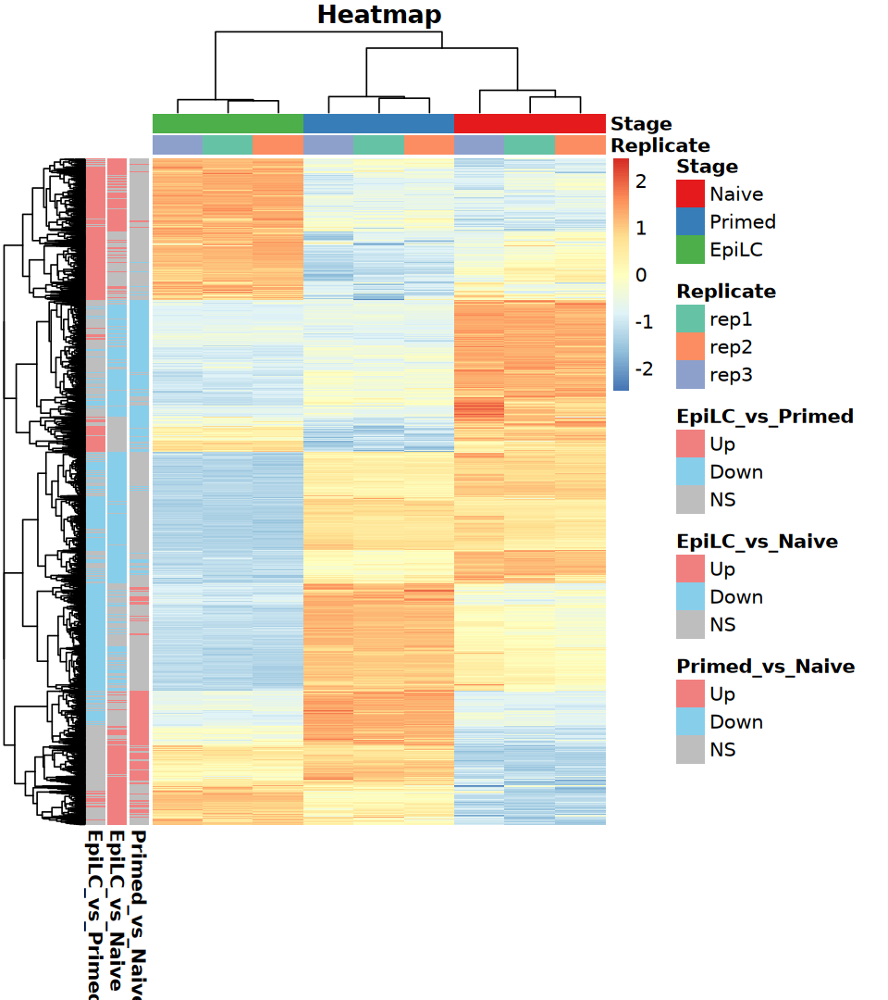

In [78]:
options(repr.plot.width = 8, repr.plot.height = 9)
pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [79]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [80]:
heatmap_dat <- deg_df |>
    filter(result %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(idx) norm_mat[idx, ])()

In [81]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = rev(brewer.pal(n = 3, name = "RdYlBu")))

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Stage)),
    levels(dds$Stage))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [82]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Stage, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Stage = group_colors, 
        Replicate = replicate_colors))

In [83]:
ar <- deg_df |> 
    dplyr::select(gene_id, contrast, DEG = result) |>
    pivot_wider(names_from = contrast, values_from = DEG) |> 
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(contrast_labels))

anno_colors <- setNames(
    replicate(length(contrast_labels), deg_colors, simplify = FALSE), 
    contrast_labels)

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [84]:
gene_labels <- deg_df |>
    dplyr::filter(!is.na(label)) |>
    dplyr::select(gene_id, label)

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$label[
    match(rownames(heatmap_dat)[mark_rows], gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)))

In [85]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)

lg_group <- Legend(
    title = "Stage", labels = levels(dds$Stage))

lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))

lg_deg <- Legend(
    labels = levels(deg_df$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [86]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        # right_annotation = right_anno,
        show_row_names = FALSE, 
        show_column_names = FALSE, 
        use_raster = TRUE)

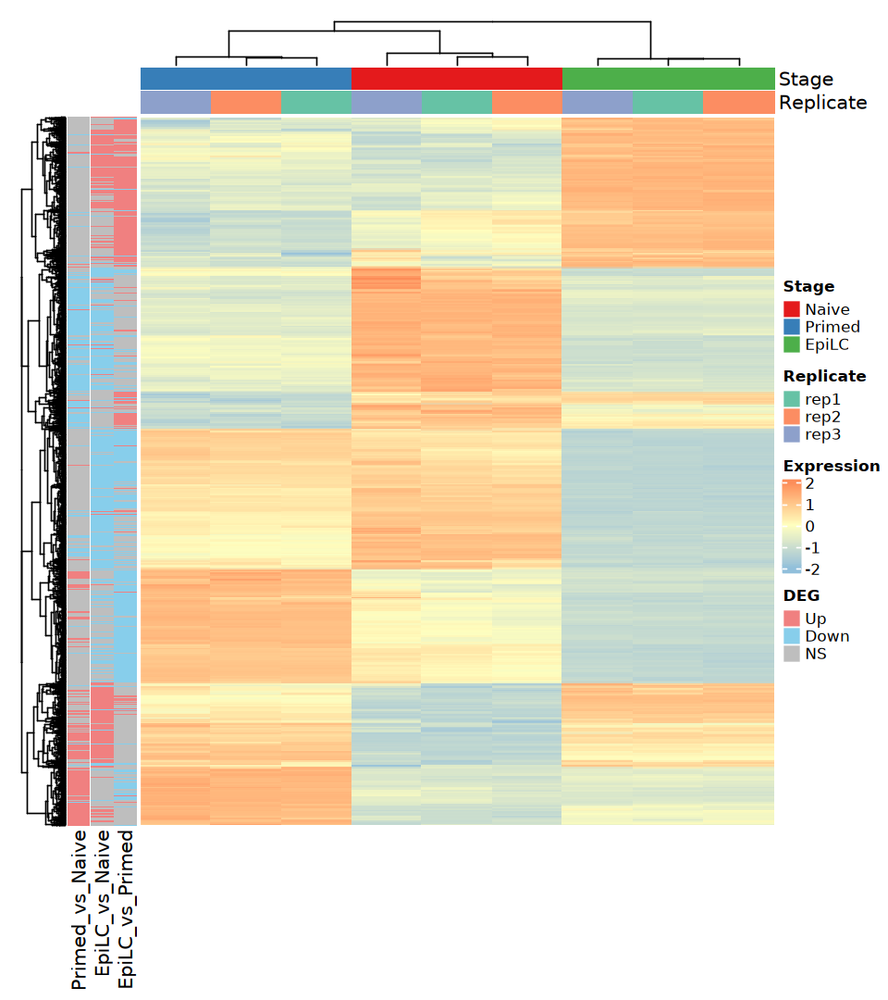

In [87]:
options(repr.plot.width = 8, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE, 
    annotation_legend_list = list(lg_deg), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"), 
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(5, 5, 5, 5), "mm"))

### Sankey Plot

In [88]:
suppressPackageStartupMessages(library(ggalluvial))

In [89]:
sankey_long <- deg_df |> 
    dplyr::select(gene_id, contrast, result) |>
    mutate(result = factor(result, levels = c("Up", "NS", "Down"))) |>
    group_by(gene_id) |>
    filter(any(result != "NS")) |>
    ungroup()

head(sankey_long)

gene_id,contrast,result
<chr>,<fct>,<fct>
ENSMUSG00000026380,EpiLC_vs_Naive,Down
ENSMUSG00000031155,EpiLC_vs_Naive,Up
ENSMUSG00000020661,EpiLC_vs_Naive,Up
ENSMUSG00000021255,EpiLC_vs_Naive,Down
ENSMUSG00000047751,EpiLC_vs_Naive,Up
ENSMUSG00000095180,EpiLC_vs_Primed,Up


In [90]:
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

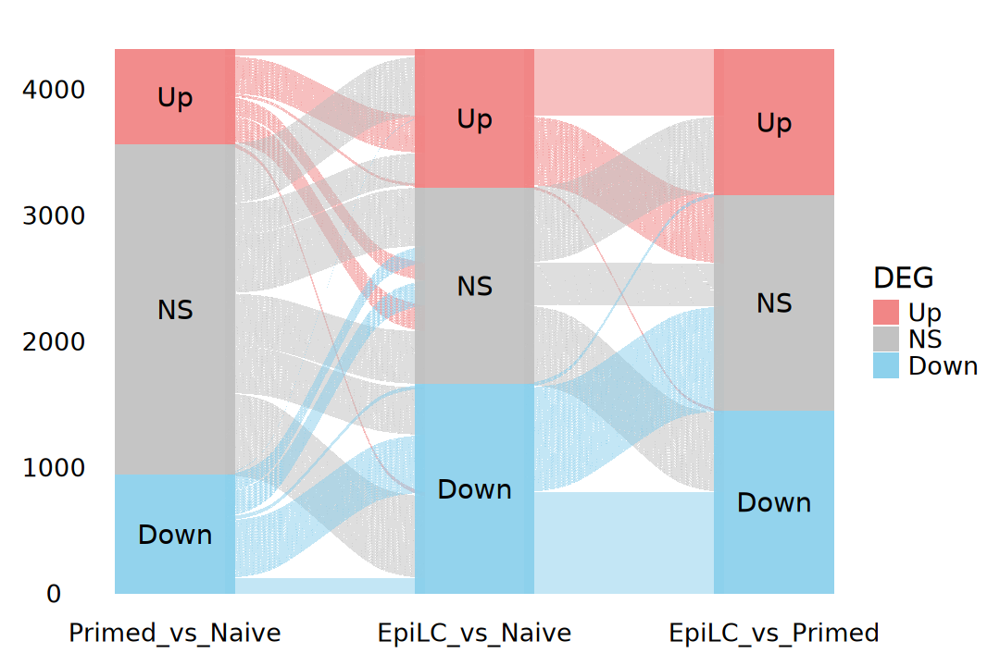

In [91]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(
    sankey_long, aes(
        x = contrast, stratum = result, alluvium = gene_id,
        y = 1, fill = result, label = result)) +
    geom_flow(stat = "alluvium") +
    geom_stratum(width = 0.4, alpha = 0.9, color = NA) +
    geom_text(stat = "stratum", size = 6) +
    scale_x_discrete(limits = contrast_labels, expand = c(.1, .1)) +
    scale_fill_manual(values = deg_colors) +
    labs(x = "Comparisons", y = "Gene count", fill = "DEG") +
    theme_void() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_blank(),
        axis.text = element_text(size = 16))

In [92]:
sankey_wide <- deg_df |> 
    dplyr::select(gene_id, contrast, result) |>
    mutate(result = factor(result, levels = c("Up", "NS", "Down"))) |>
    pivot_wider(names_from = contrast, values_from = result) |> 
    filter(if_any(all_of(contrast_labels), ~ .x != "NS")) |>
    group_by(across(all_of(contrast_labels))) |>
    summarise(Freq = n(), .groups = "drop")

head(sankey_wide)

Primed_vs_Naive,EpiLC_vs_Naive,EpiLC_vs_Primed,Freq
<fct>,<fct>,<fct>,<int>
Up,Up,Up,52
Up,Up,NS,293
Up,Up,Down,24
Up,NS,NS,143
Up,NS,Down,208
Up,Down,Down,32


Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”


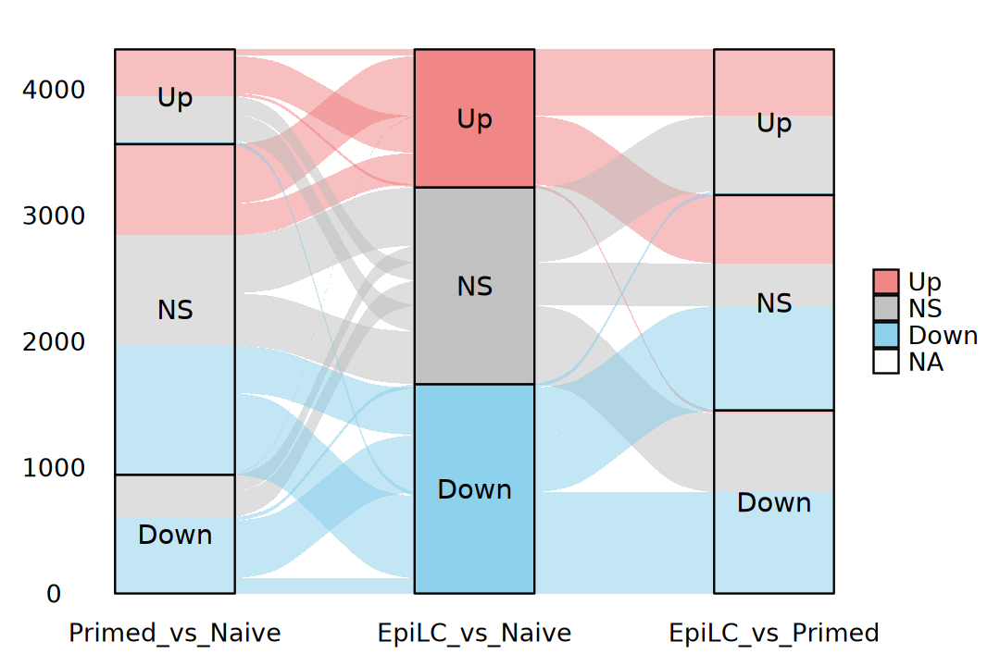

In [93]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(
    sankey_wide, aes(
        axis1 = Primed_vs_Naive, 
        axis2 = EpiLC_vs_Naive,
        axis3 = EpiLC_vs_Primed,
        y = Freq, 
        fill = EpiLC_vs_Naive)) +
    geom_alluvium(width = 0.4, alpha = 0.5) +
    geom_stratum(width = 0.4, alpha = 0.9, color = "black") +
    geom_text(
        aes(label = after_stat(stratum)), stat = "stratum", size = 6) +
    scale_x_discrete(limits = contrast_labels, expand = c(.1, .1)) +
    scale_fill_manual(values = deg_colors, na.value = NA) +
    labs(
        x = "Comparisons", y = "Gene count", 
        fill = "Status in Primed_vs_Naive") +
    theme_void() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_blank(), 
        legend.text = element_text(size = 16),
        axis.title = element_blank(),
        axis.text = element_text(size = 16))

# 6. Time-course Dynamics

## 1). DEGs: Dynamic Gene Selection

### a). DESeq2 (LRT)

> The likelihood ratio test (LRT) is useful for testing multiple terms at once, for example testing 3 or more levels of a factor at once, or all interactions between two variables. The LRT for count data is conceptually similar to an analysis of variance (ANOVA) calculation in linear regression, except that in the case of the Negative Binomial GLM, we use an analysis of deviance (ANODEV), where the deviance captures the difference in likelihood between a full and a reduced model.
> - Identifies genes with significant expression dynamics across conditions. By comparing the full factors model against a reduced model, LRT filters out invariant baseline features and captures any temporal patterns  (e.g., monotonic or wave-like), serving as a crucial input for clustering.

In [94]:
design(dds)

~0 + Stage

In [95]:
dds <- DESeq(dds, test = "LRT", reduced = ~ 1)

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [96]:
deseq2_lrt_result <- results(dds) |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NS") |> 
            factor(levels = c("Sig", "NS"))) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lrt_result$result)
head(deseq2_lrt_result)


  Sig    NS 
10124  3911 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000073295,77.45881,6.990644,0.1456979,59.426221,1.246694e-13,2.582255e-13,Sig,Nudt11,protein_coding,3036
ENSMUSG00000073294,68.46146,6.064507,0.1719673,13.158256,1.389060e-03,1.682383e-03,NS,AU022751,protein_coding,2201
ENSMUSG00000073293,24.83732,4.727099,0.2625455,8.517671,1.413876e-02,1.602370e-02,NS,Nudt10,protein_coding,1775
ENSMUSG00000068270,119.62308,7.502625,0.1256970,232.107398,3.967518e-51,2.947809e-50,Sig,Shroom4,protein_coding,8880
ENSMUSG00000062393,23.86555,3.384928,0.3601804,98.312345,4.484824e-22,1.319315e-21,Sig,Dgkk,protein_coding,7158
ENSMUSG00000004317,279.43458,7.541590,0.1003416,130.102833,5.604397e-29,2.108895e-28,Sig,Clcn5,protein_coding,11452


### b). edgeR (ANOVA-like)

> ANOVA-like test for any differences. In edgeR, this is done by specifying multiple coefficients to glmQLFTest or glmLRT, when the design matrix includes an intercept term.

In [97]:
design <- model.matrix(~ group, data = dgel$samples)

In [98]:
dgel <- estimateDisp(dgel, design)
fit <- glmQLFit(dgel, design)
qlft <- glmQLFTest(fit, coef = 2:ncol(design))

In [99]:
edgeR_anova_result <- topTags(qlft, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < 1e-5  ~ "Sig", TRUE ~ "NS") |>
            factor(levels = c("Sig", "NS")))

table(edgeR_anova_result$result)
head(edgeR_anova_result)


 Sig   NS 
8018 5953 

,seqnames,start,end,width,strand,symbol,type,basepairs,logFC.groupPrimed,logFC.groupEpiLC,logCPM,F,pvalue,padj,result
,<fct>,<int>,<int>,<int>,<fct>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000029337,chr5,98254184,98277030,22847,+,Fgf5,protein_coding,2501,5.187913,10.285893,5.522896,1285.512,8.919051e-19,1.246081e-14,Sig
ENSMUSG00000028786,chr4,129105548,129111626,6079,+,Tmem54,protein_coding,1222,6.162724,10.832621,4.748402,1048.122,2.041525e-18,1.426107e-14,Sig
ENSMUSG00000031155,chrX,7878262,7883432,5171,+,Pim2,protein_coding,2795,2.587839,6.091995,8.444938,1780.163,5.747140e-18,2.676443e-14,Sig
ENSMUSG00000030523,chr7,64153835,64269775,115941,+,Trpm1,protein_coding,14746,-8.520908,-9.739227,6.143208,1421.112,7.884253e-18,2.753772e-14,Sig
ENSMUSG00000000805,chr11,84957786,84966044,8259,+,Car4,protein_coding,1966,5.850819,10.208982,6.423401,1367.738,1.425868e-17,3.984162e-14,Sig
ENSMUSG00000075304,chr2,70474923,70477729,2807,+,Sp5,protein_coding,2100,-3.837429,-9.350925,5.854414,1233.190,2.130593e-17,4.306042e-14,Sig


In [100]:
comparison_df <- deseq2_lrt_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, result_deseq2 = result) |> 
    inner_join(
        edgeR_anova_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, result_edger = result),
        by = c("gene_id"))

cat("\n=========================================\n")
cat("Contrast:", "Stages", "\n")
cat("=========================================\n")
print(table(
    DESeq2 = comparison_df$result_deseq2, 
    edgeR = comparison_df$result_edger))


Contrast: Stages 
      edgeR
DESeq2  Sig   NS
   Sig 7996 2116
   NS     2 3761


In [101]:
genes <- list(
    Primed_vs_Naive = deseq2_result_df$symbol[
        deseq2_result_df$result %in% c("Up", "Down") & 
        deseq2_result_df$contrast == "Primed_vs_Naive"],
    EpiLC_vs_Naive = deseq2_result_df$symbol[
        deseq2_result_df$result %in% c("Up", "Down") & 
        deseq2_result_df$contrast == "EpiLC_vs_Naive"], 
    EpiLC_vs_Primed = deseq2_result_df$symbol[
        deseq2_result_df$result %in% c("Up", "Down") & 
        deseq2_result_df$contrast == "EpiLC_vs_Primed"],
    LRT = deseq2_lrt_result[deseq2_lrt_result$result %in% c("Sig"),]$symbol)

genes <- lapply(genes, unique)

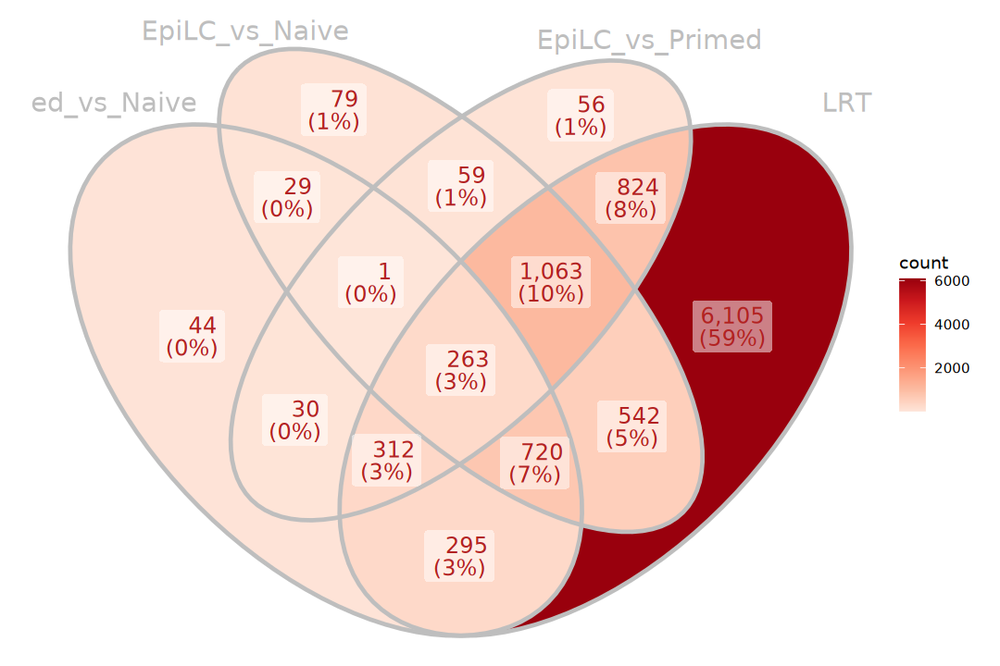

In [102]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggVennDiagram::ggVennDiagram(
    genes, set_color = "grey", set_size = 6,
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

In [103]:
genes <- list(
    Primed_vs_Naive = edger_qlf_result_df$symbol[
        edger_qlf_result_df$result %in% c("Up", "Down") & 
        edger_qlf_result_df$contrast == "Primed_vs_Naive"],
    EpiLC_vs_Naive = edger_qlf_result_df$symbol[
        edger_qlf_result_df$result %in% c("Up", "Down") & 
        edger_qlf_result_df$contrast == "EpiLC_vs_Naive"], 
    EpiLC_vs_Primed = edger_qlf_result_df$symbol[
        edger_qlf_result_df$result %in% c("Up", "Down") & 
        edger_qlf_result_df$contrast == "EpiLC_vs_Primed"],
    ANOVA = edgeR_anova_result[edgeR_anova_result$result %in% c("Sig"),]$symbol)

genes <- lapply(genes, unique)

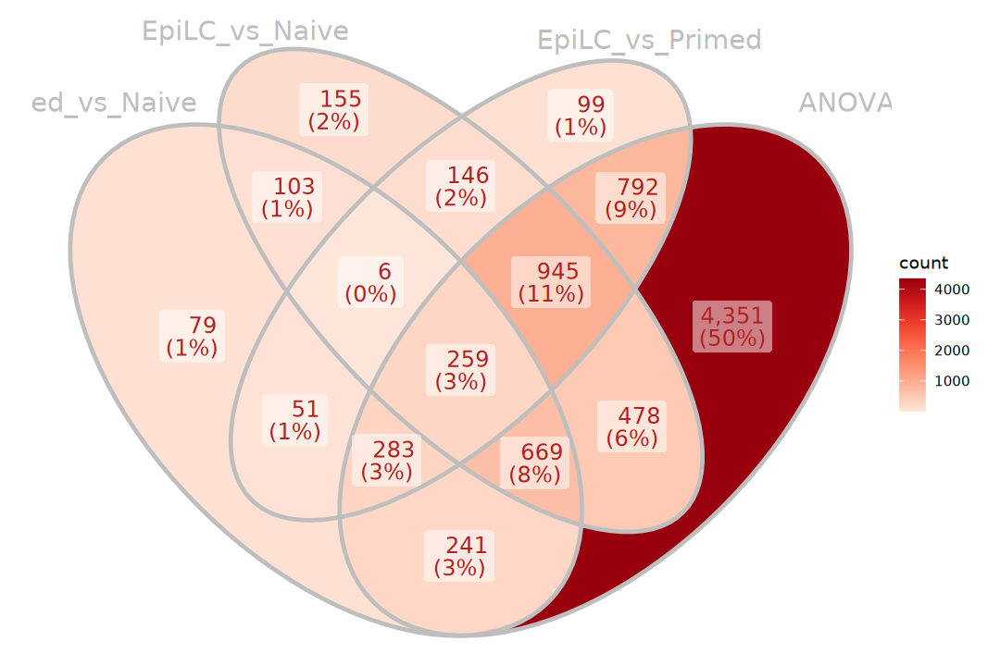

In [104]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggVennDiagram::ggVennDiagram(
    genes, set_color = "grey", set_size = 6,
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

## 2). Trend Clustering

> It is recommended to use genes with significant differential expression to enhance computational efficiency. Of course, all genes can also be selected for cluster analysis.

In [105]:
sig_gene_ids <- deseq2_lrt_result |> 
    dplyr::filter(result == "Sig") |> rownames()

message(
    "Number of time-significantly dynamic genes identified by LRT:", 
    length(sig_gene_ids), "\n")

Number of time-significantly dynamic genes identified by LRT:10124




In [106]:
norm_tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
norm_ltpm <- log2(norm_tpm + 1)
norm_mat <- norm_ltpm[sig_gene_ids, ]

# rld_mat <- assay(rlog(dds, blind = FALSE))
# vst_mat <- assay(vst(dds, blind = FALSE))
# norm_mat <- vst_mat[sig_gene_ids, ]

In [107]:
stages <- eSet$Stage

norm_mean_mat <- sapply(stage_levels, function(stage) {
    rowMeans(norm_mat[, stages == stage, drop = FALSE])
})

print(dim(norm_mean_mat))
print(head(norm_mean_mat))

# dds_mean <- collapseReplicates(dds, groupby = dds$Stage)

[1] 10124     3


                       Naive   Primed     EpiLC
ENSMUSG00000073295 2.3816482 3.240300 3.2082511
ENSMUSG00000068270 0.7230459 3.004855 2.3343108
ENSMUSG00000062393 0.2462541 2.041149 0.3585254
ENSMUSG00000004317 2.8265424 4.001029 2.0752526
ENSMUSG00000046269 2.7026127 3.599581 1.6621089
ENSMUSG00000063018 3.6033933 5.169417 6.5041876


### a). Mfuzz

> Soft clustering: fuzzy c-means algorithm (of the e1071 package) based on minimization of a weighted square error function.

In [108]:
suppressPackageStartupMessages(library(Mfuzz))

Warning message:
“no DISPLAY variable so Tk is not available”


In [109]:
# Filtering of genes based on their standard deviation
cl_eset <- ExpressionSet(assayData = norm_mean_mat) |>
    filter.std(min.std = 0.5, visu = FALSE) |>
    standardise()
cl_eset

2467 genes excluded.


ExpressionSet (storageMode: lockedEnvironment)
assayData: 7657 features, 3 samples 
  element names: exprs 
protocolData: none
phenoData: none
featureData: none
experimentData: use 'experimentData(object)'
Annotation:  

In [110]:
# Estimate for optimal fuzzifier m
m_val <- mestimate(cl_eset)
message(paste0("fuzzifier m: ", m_val))

set.seed(123)
cl_mfuzz <- mfuzz(cl_eset, c = 6, m = 1.5)
cl_mfuzz$cluster |> table()

fuzzifier m: 3.6154958755998




   1    2    3    4    5    6 
 978  686 1205 2345 1722  721 

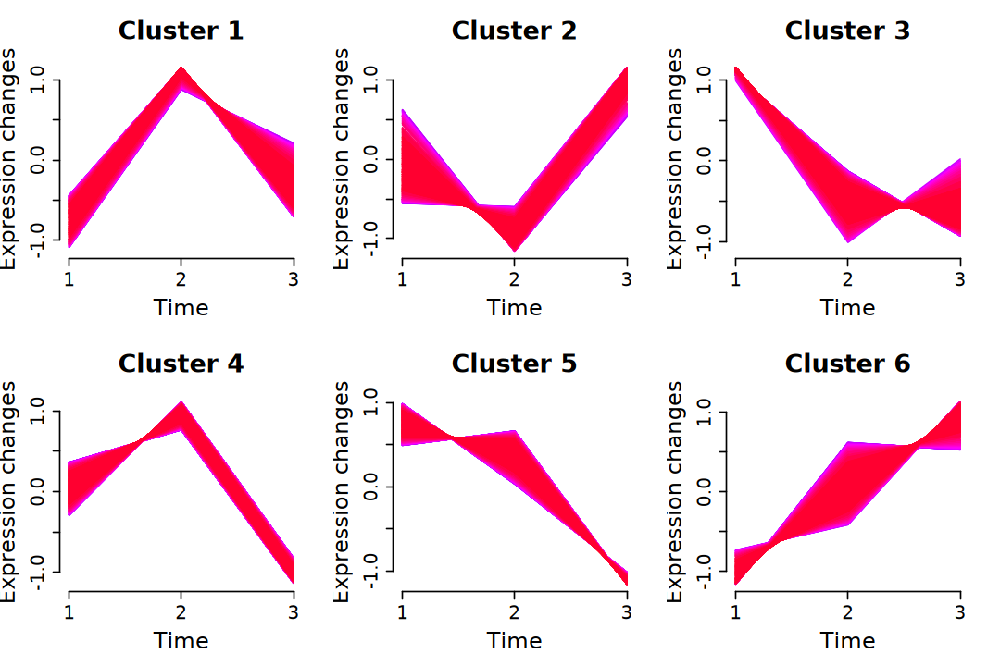

In [111]:
options(repr.plot.width = 9, repr.plot.height = 6)

mfuzz.plot2(
    cl_eset, cl = cl_mfuzz, mfrow = c(2, 3), 
    min.mem = 0.8, x11 = FALSE, cex.main = 2,
    cex.lab = 1.8, cex.axis = 1.5)

### b). TCseq

In [112]:
suppressPackageStartupMessages(library(TCseq))

Warning message:
“replacing previous import ‘e1071::element’ by ‘ggplot2::element’ when loading ‘TCseq’”


In [113]:
norm_mean_filtered_tpm <- norm_mean_mat[rowSds(norm_mean_mat) >= 0.5, ]

set.seed(123)
cl_tcseq <- timeclust(
    norm_mean_filtered_tpm, algo = "cm", k = 6, standardize = TRUE)
cl_tcseq@cluster |> table()


   1    2    3    4    5    6 
1069  703 1239 2255 1677  714 

Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the TCseq package.
  Please report the issue to the authors.”


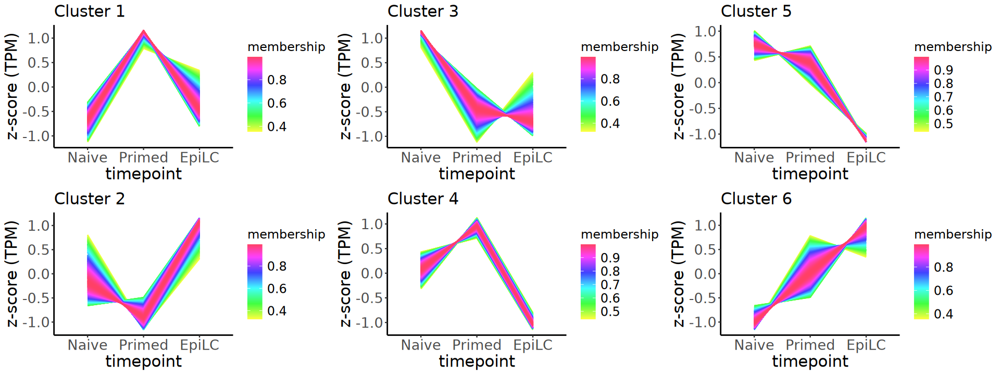

In [114]:
options(repr.plot.width = 16, repr.plot.height = 6)

p <- timeclustplot(cl_tcseq, value = "z-score (TPM)", cols = 3)

### [TiSA](https://github.com/Ylefol/TimeSeriesAnalysis)?

PART clustering

- Yohan Lefol, Tom Korfage, Robin Mjelle, Christian Prebensen, Torben Lüders, Bruno Müller, Hans Krokan, Antonio Sarno, Lene Alsøe, CONSORTIUM LEMONAID, Jan-Erik Berdal, Pål Sætrom, Hilde Nilsen, Diana Domanska, TiSA: TimeSeriesAnalysis—a pipeline for the analysis of longitudinal transcriptomics data, NAR Genomics and Bioinformatics, Volume 5, Issue 1, March 2023, lqad020, https://doi.org/10.1093/nargab/lqad020.

## 3). Regression

### a). maSigPro

> maSigPro follows a two-step regression strategy to find genes with significant temporal expression changes and significant differences between experimental groups.

In [115]:
suppressPackageStartupMessages(library(maSigPro))

In [116]:
design_df <- colData(eSet) |> as.data.frame() |> 
    mutate(
        Time = as.integer(Stage), 
        Replicate = as.integer(Replicate), 
        Group = 1) |> 
    dplyr::select(Time, Replicate, Group) |>
    arrange(Time, Replicate)

design_df

,Time,Replicate,Group
,<int>,<int>,<dbl>
Naive_rep1,1,1,1
Naive_rep2,1,2,1
Naive_rep3,1,3,1
Primed_rep1,2,1,1
Primed_rep2,2,2,1
Primed_rep3,2,3,1
EpiLC_rep1,3,1,1
EpiLC_rep2,3,2,1
EpiLC_rep3,3,3,1


In [117]:
# Defining the regression model
# degree = time points - 1
# Usually, a polynomial of degree 2 is more than enough to model the gene expression, 
# although a degree 3 may be appropriate in experacimental setups with a big number of
# time points.
design <- make.design.matrix(design_df, degree = 2)

In [118]:
# dgel <- estimateGLMCommonDisp(dgel, design = design)
# phi <- dgel$common.dispersion
# theta <- 1/phi
1 / dgel$common.dispersion

[1] 89.69483

In [119]:
# DEseq2
# norm_counts <- counts(dds, normalized = TRUE)

# # edgeR
# eff_lib_size <- dgel$samples$lib.size * dgel$samples$norm.factors
# norm_counts <- t(t(dgel$counts) / eff_lib_size) * mean(eff_lib_size)

# TPM
norm_counts <- norm_ltpm

In [120]:
# Performs regression analysis for each gene to identify significant ones.
fit <- p.vector(
    norm_counts, design, counts = TRUE, 
    theta = 90, Q = 0.05, MT.adjust = "BH")

[1] "fitting  gene 100 out of 14035"
[1] "fitting  gene 200 out of 14035"
[1] "fitting  gene 300 out of 14035"
[1] "fitting  gene 400 out of 14035"
[1] "fitting  gene 500 out of 14035"
[1] "fitting  gene 600 out of 14035"
[1] "fitting  gene 700 out of 14035"
[1] "fitting  gene 800 out of 14035"
[1] "fitting  gene 900 out of 14035"
[1] "fitting  gene 1000 out of 14035"
[1] "fitting  gene 1100 out of 14035"
[1] "fitting  gene 1200 out of 14035"
[1] "fitting  gene 1300 out of 14035"
[1] "fitting  gene 1400 out of 14035"
[1] "fitting  gene 1500 out of 14035"
[1] "fitting  gene 1600 out of 14035"
[1] "fitting  gene 1700 out of 14035"
[1] "fitting  gene 1800 out of 14035"
[1] "fitting  gene 1900 out of 14035"
[1] "fitting  gene 2000 out of 14035"
[1] "fitting  gene 2100 out of 14035"
[1] "fitting  gene 2200 out of 14035"
[1] "fitting  gene 2300 out of 14035"
[1] "fitting  gene 2400 out of 14035"
[1] "fitting  gene 2500 out of 14035"
[1] "fitting  gene 2600 out of 14035"
[1] "fitting  gene 27

In [121]:
print(fit$i)

[1] 13306


In [122]:
# Selects the best regression model for each gene using stepwise regression.
tstep <- T.fit(fit, step.method = "backward", alfa = 0.05)

[1] "fitting  gene 100 out of 13306"
[1] "fitting  gene 200 out of 13306"
[1] "fitting  gene 300 out of 13306"
[1] "fitting  gene 400 out of 13306"
[1] "fitting  gene 500 out of 13306"
[1] "fitting  gene 600 out of 13306"
[1] "fitting  gene 700 out of 13306"
[1] "fitting  gene 800 out of 13306"
[1] "fitting  gene 900 out of 13306"
[1] "fitting  gene 1000 out of 13306"
[1] "fitting  gene 1100 out of 13306"
[1] "fitting  gene 1200 out of 13306"
[1] "fitting  gene 1300 out of 13306"
[1] "fitting  gene 1400 out of 13306"
[1] "fitting  gene 1500 out of 13306"
[1] "fitting  gene 1600 out of 13306"
[1] "fitting  gene 1700 out of 13306"
[1] "fitting  gene 1800 out of 13306"
[1] "fitting  gene 1900 out of 13306"
[1] "fitting  gene 2000 out of 13306"
[1] "fitting  gene 2100 out of 13306"
[1] "fitting  gene 2200 out of 13306"
[1] "fitting  gene 2300 out of 13306"
[1] "fitting  gene 2400 out of 13306"
[1] "fitting  gene 2500 out of 13306"
[1] "fitting  gene 2600 out of 13306"
[1] "fitting  gene 27

In [123]:
sigs <- get.siggenes(tstep, rsq = 0.6, vars = "all")

In [124]:
summary(sigs)
sig_gene_ids <- sigs$summary

cat("Number of significant time-varying genes:", length(sig_gene_ids), "\n")

          Length Class  Mode     
sig.genes     7  -none- list     
summary   11382  -none- character

Number of significant time-varying genes: 11382 


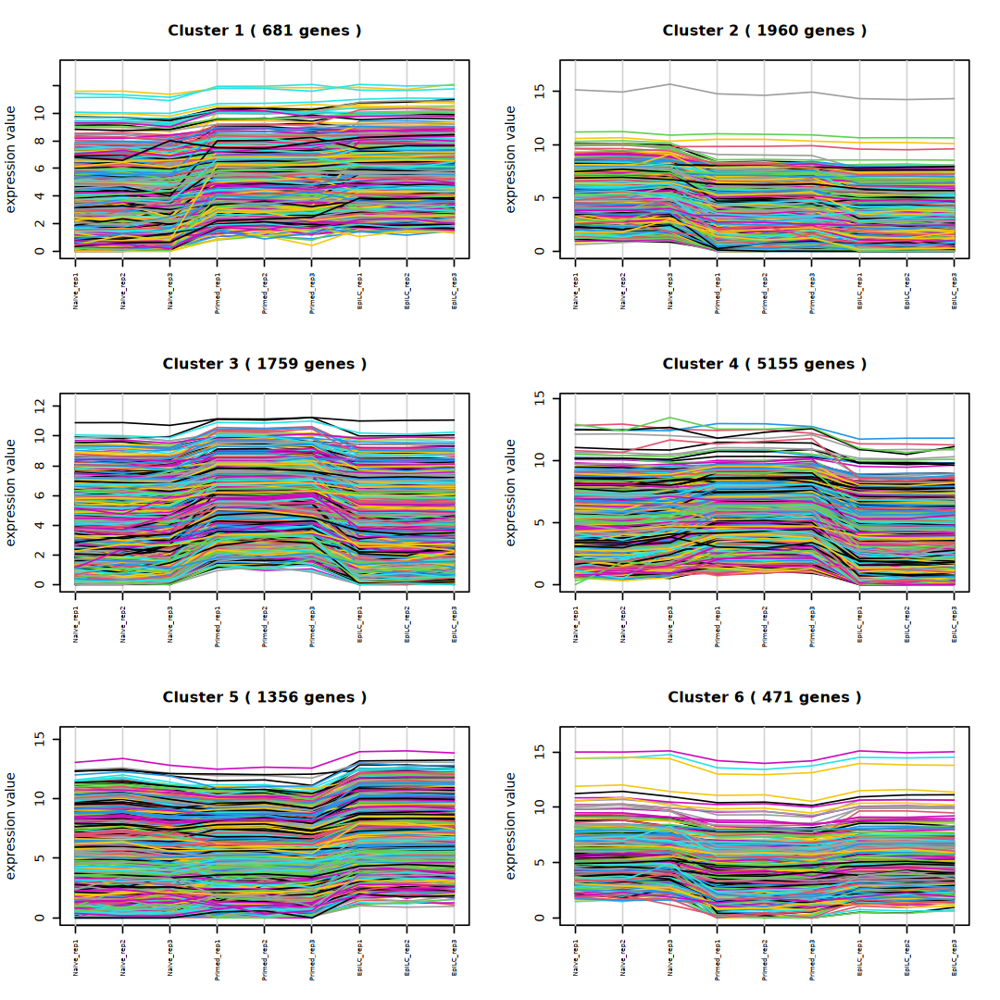

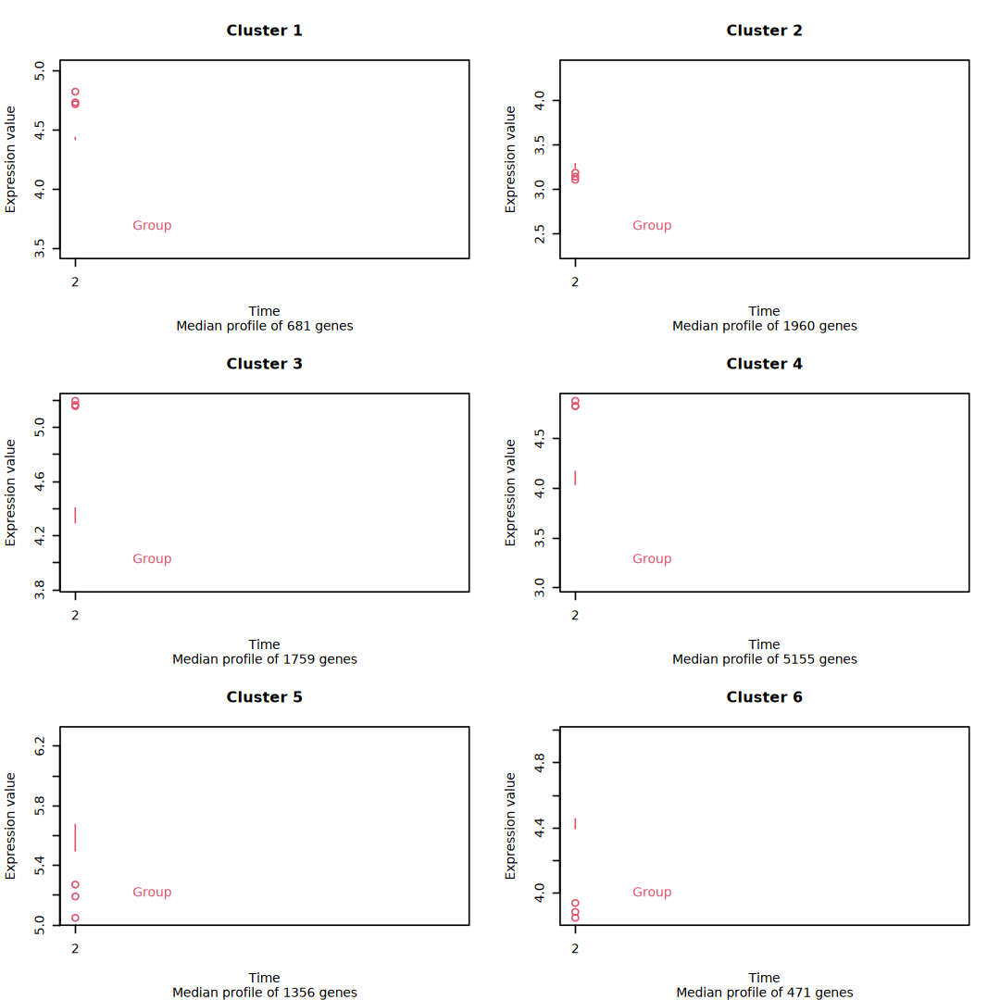

In [125]:
options(repr.plot.width = 9, repr.plot.height = 9)
cl_masigpro <- see.genes(sigs$sig.genes, k = 6)

In [126]:
cl_masigpro$cut |> table()


   1    2    3    4    5    6 
 681 1960 1759 5155 1356  471 

## 4). WGCNA

## 5). Impulse Model

### ImpulseDE2?
- David S Fischer, Fabian J Theis, Nir Yosef, Impulse model-based differential expression analysis of time course sequencing data, Nucleic Acids Research, Volume 46, Issue 20, 16 November 2018, Page e119, https://doi.org/10.1093/nar/gky675.

In [127]:
# library(ImpulseDE2)
# # inputData: data.frame(sample, time, condition), raw counts矩阵
# res <- runImpulseDE2(matCount = counts, dfAnnotation = meta,
#                     boolCaseCtrl = FALSE, scaNProc = 4)
# head(res$vecDEGene)

## Clustering Evaluation

### Adjusted Rand Index, ARI

In [128]:
suppressPackageStartupMessages(library(mclust))

In [129]:
gene_lists <- list(
    names(cl_mfuzz$cluster),
    names(cl_tcseq@cluster),
    names(cl_masigpro$cut))

common_genes <- Reduce(intersect, gene_lists)

vector_mfuzz    <- cl_mfuzz$cluster[common_genes]
vector_tcseq    <- cl_tcseq@cluster[common_genes]
vector_masigpro <- cl_masigpro$cut[common_genes]

In [130]:
ari_mfuzz_tcseq    <- adjustedRandIndex(vector_mfuzz, vector_tcseq)
ari_mfuzz_masigpro <- adjustedRandIndex(vector_mfuzz, vector_masigpro)
ari_tcseq_masigpro <- adjustedRandIndex(vector_tcseq, vector_masigpro)

cat("ARI (Mfuzz vs tcseq):", ari_mfuzz_tcseq, "\n")
cat("ARI (Mfuzz vs maSigPro):", ari_mfuzz_masigpro, "\n")
cat("ARI (tcseq vs maSigPro):", ari_tcseq_masigpro, "\n")

ARI (Mfuzz vs tcseq): 0.9443496 
ARI (Mfuzz vs maSigPro): 0.5088594 
ARI (tcseq vs maSigPro): 0.5391441 


### Jaccard Similarity

In [131]:
table_match <- table(vector_mfuzz, vector_tcseq)

jaccard_matrix <- matrix(
    0, nrow=nrow(table_match), ncol=ncol(table_match),
    dimnames=list(
        paste0("Mfuzz_C", rownames(table_match)), 
        paste0("TCseq_C", colnames(table_match))))

for(i in 1:nrow(table_match)) {
    for(j in 1:ncol(table_match)) {
        intersection <- table_match[i, j]
        union_size <- sum(vector_mfuzz == rownames(table_match)[i]) + 
            sum(vector_tcseq == colnames(table_match)[j]) - intersection
        jaccard_matrix[i, j] <- intersection / union_size
    }
}

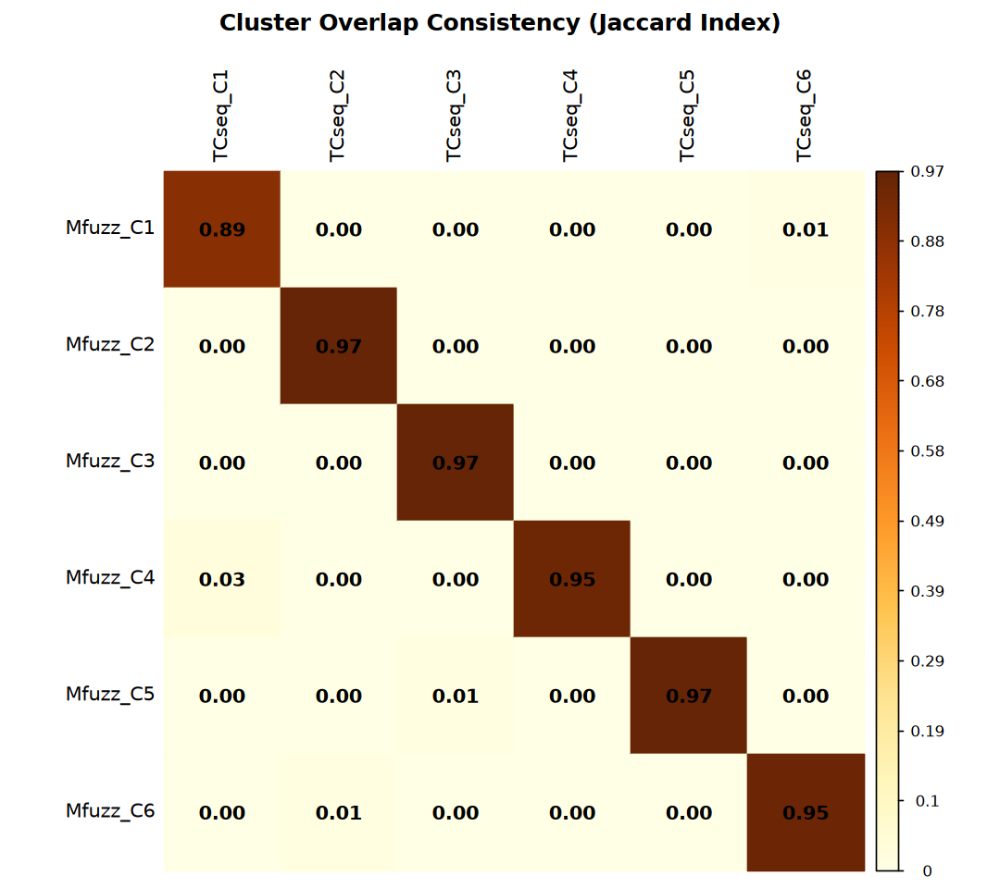

In [132]:
options(repr.plot.width = 9, repr.plot.height = 8)
corrplot::corrplot(
    jaccard_matrix, is.corr = FALSE, method = "color", 
    addCoef.col = "black", tl.col = "black", 
    title = "Cluster Overlap Consistency (Jaccard Index)", 
    mar = c(0,0,2,0))

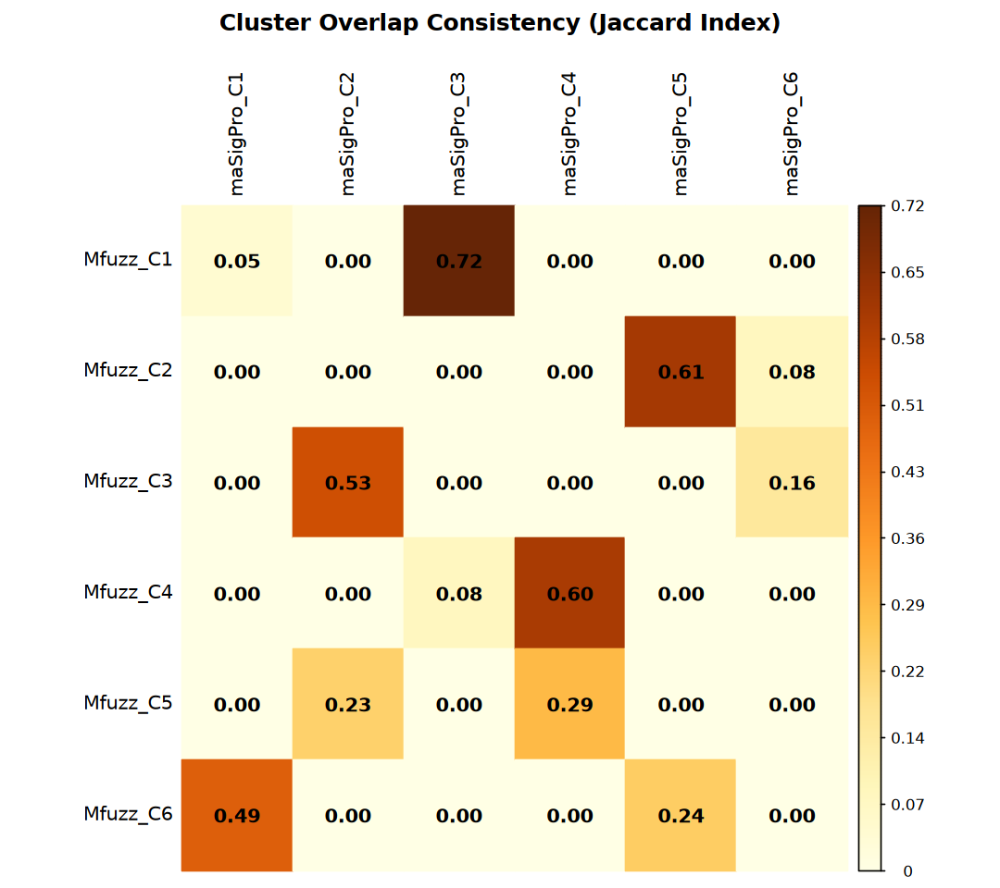

In [133]:
table_match <- table(vector_mfuzz, vector_masigpro)

jaccard_matrix <- matrix(
    0, nrow=nrow(table_match), ncol=ncol(table_match),
    dimnames=list(
        paste0("Mfuzz_C", rownames(table_match)), 
        paste0("maSigPro_C", colnames(table_match))))

for(i in 1:nrow(table_match)) {
    for(j in 1:ncol(table_match)) {
        intersection <- table_match[i, j]
        union_size <- sum(vector_mfuzz == rownames(table_match)[i]) + 
            sum(vector_masigpro == colnames(table_match)[j]) - intersection
        jaccard_matrix[i, j] <- intersection / union_size
    }
}

options(repr.plot.width = 9, repr.plot.height = 8)
corrplot::corrplot(
    jaccard_matrix, is.corr = FALSE, method = "color", 
    addCoef.col = "black", tl.col = "black", 
    title = "Cluster Overlap Consistency (Jaccard Index)", 
    mar = c(0,0,2,0))

## Clustering Visualization

### Lineplot

In [134]:
norm_mat <- log2(tpm + 1)

In [135]:
norm_expr_df <- norm_mat |> as.data.frame() |>
    rownames_to_column(var = "gene_id") |>
    pivot_longer(cols = -gene_id, names_to = "sample", values_to = "value")

In [136]:
plot_lineplot <- function(cluster, expression, coldata, group, method) {
    data.frame(cluster = cluster) |>
        rownames_to_column(var = "gene_id") |>
        mutate(cluster = factor(paste0("cluster", cluster))) |>
        add_count(cluster, name = "count") |>
        left_join(expression, by = "gene_id") |>
        left_join(coldata, by = "sample") |>
        group_by(across(all_of(group)), Replicate, cluster, count) |>
        summarize(
            median_value = median(value, na.rm = TRUE), 
            .groups = "drop") |>
        mutate(
            cluster_label = paste0(cluster, " (n=", count, ")"),
            cluster_label = factor(cluster_label)) |>
        ungroup() |>
    ggplot(aes(x = .data[[group]], y = median_value)) +
        # geom_point(position = position_jitter(width = 0.1), alpha = 0.7) + 
        stat_summary(
            aes(color = cluster_label, group = cluster_label), 
            fun = mean, geom = "line", linewidth = 1, alpha = 0.8) +
        stat_summary(
            aes(color = cluster_label, group = cluster_label), 
            fun.data = mean_se, geom = "errorbar", width = 0.1) +
        scale_x_discrete(expand = expansion(mult = c(0.1, 0.1))) +
        scale_y_continuous(expand = expansion(mult = c(0.1, 0.1))) +
        scale_color_brewer(palette = "Dark2") +
        labs(
            title = paste0("Time-course: ", method), 
            color = "Cluster", x = NULL, y = "Median Expression") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16))
}

In [137]:
coldata <- colData(eSet) |> as.data.frame() |> 
    rownames_to_column(var = "sample")

p1 <- plot_lineplot(
    cluster = cl_mfuzz$cluster, expression = norm_expr_df, 
    coldata = coldata, group = "Stage", method = "Mfuzz")
p2 <- plot_lineplot(
    cluster = cl_tcseq@cluster, expression = norm_expr_df, 
    coldata = coldata, group = "Stage", method = "TCseq")
p3 <- plot_lineplot(
    cluster = cl_masigpro$cut, expression = norm_expr_df, 
    coldata = coldata, group = "Stage", method = "maSigPro")

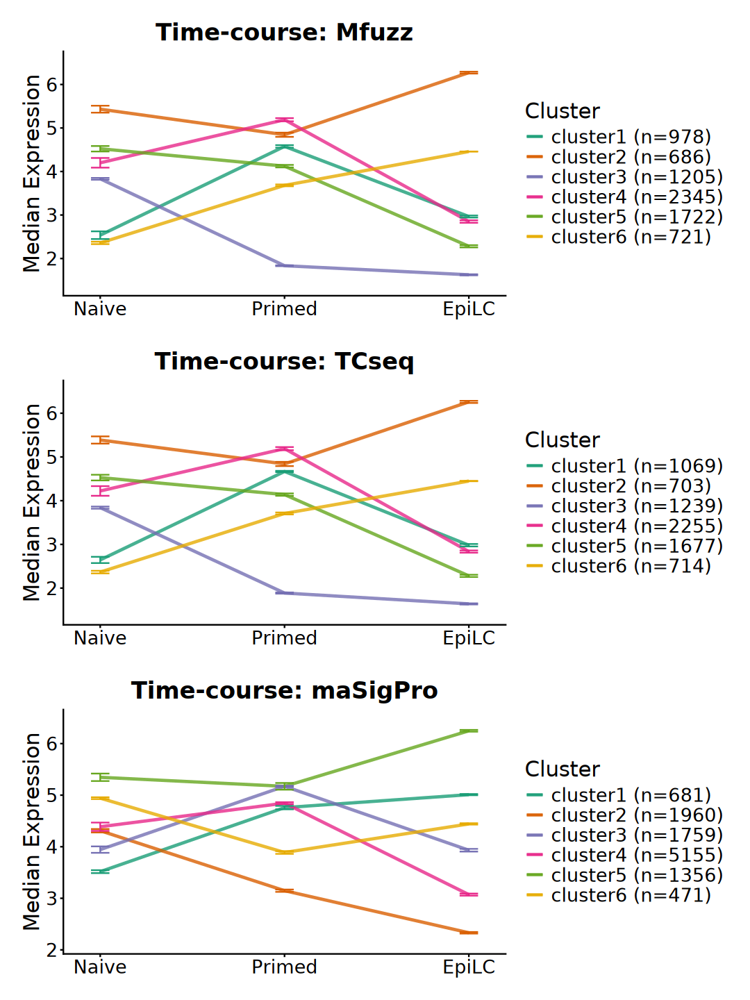

In [138]:
options(repr.plot.width = 9, repr.plot.height = 12)
p1 / p2 / p3

### Heatmap

In [139]:
ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Replicate, Stage)

In [140]:
ar <- cl_mfuzz$cluster |> data.frame(Cluster = _) |>
    mutate(Cluster = factor(paste0("cluster", Cluster))) |>
    arrange(Cluster)

In [141]:
heatmap_dat <- norm_mat[rownames(ar), ]

In [142]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Stage)),
    levels(dds$Stage))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
cluster_colors <- setNames(
    scales::brewer_pal(palette = "Set3")(nlevels(ar$Cluster)),
    levels(ar$Cluster))

anno_colors <- list(
    Stage = group_colors,
    Replicate = replicate_colors,
    Cluster = cluster_colors)

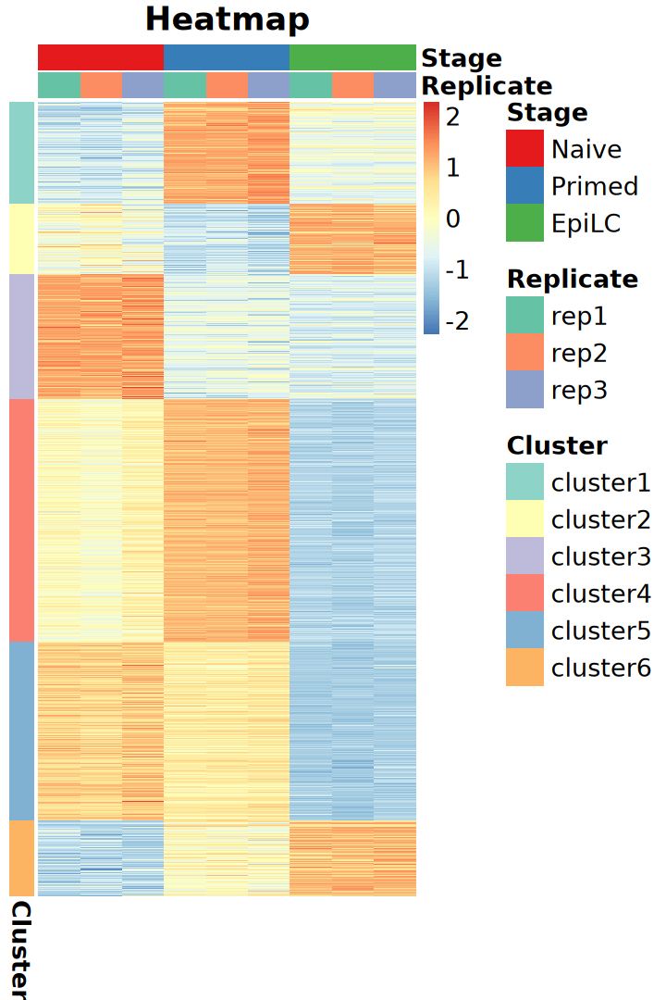

In [143]:
options(repr.plot.width = 6, repr.plot.height = 9)
pheatmap::pheatmap(
    heatmap_dat, scale = "row", 
    cluster_rows = FALSE, cluster_cols = FALSE,
    annotation_row = ar, annotation_col = ac,
    annotation_colors = anno_colors,
    main = "Heatmap", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 7. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

### Part 1

In [144]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [145]:
add_ENTREZID <- function(
    res, col, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- res[[col]]

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [146]:
deg_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deg_df$contrast, deg_df$result)

                 
                     Up  Down    NS
  Primed_vs_Naive   752   942 12341
  EpiLC_vs_Naive   1095  1661 11279
  EpiLC_vs_Primed  1156  1452 11427

In [147]:
deg_df <- add_ENTREZID(
    deg_df, "gene_id", org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
“1.74% of input gene IDs are fail to map...”


In [148]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$symbol[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    lapply(unique)

In [149]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(deg_df$SYMBOL), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [150]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,Primed_vs_Naive_Up,BP,GO:0007389,pattern specification process,110/1494,399/13103,0.2756892,2.417909,10.318373,1.682335e-19,8.702721e-16,6.592984e-16,110
2,Primed_vs_Naive_Up,BP,GO:0045165,cell fate commitment,70/1494,228/13103,0.3070175,2.692671,9.249391,2.119905e-15,5.483133e-12,4.153897e-12,70
3,Primed_vs_Naive_Up,BP,GO:2000147,positive regulation of cell motility,117/1494,496/13103,0.2358871,2.068828,8.705413,4.397896e-15,7.583439e-12,5.745041e-12,117
4,Primed_vs_Naive_Up,BP,GO:0001501,skeletal system development,108/1494,448/13103,0.2410714,2.114296,8.609053,1.117428e-14,1.445113e-11,1.094785e-11,108
5,Primed_vs_Naive_Up,BP,GO:0003002,regionalization,93/1494,362/13103,0.2569061,2.253173,8.673816,1.450577e-14,1.500767e-11,1.136947e-11,93
6,Primed_vs_Naive_Up,BP,GO:0030335,positive regulation of cell migration,113/1494,483/13103,0.2339545,2.051878,8.449982,2.442125e-14,2.002913e-11,1.517362e-11,113


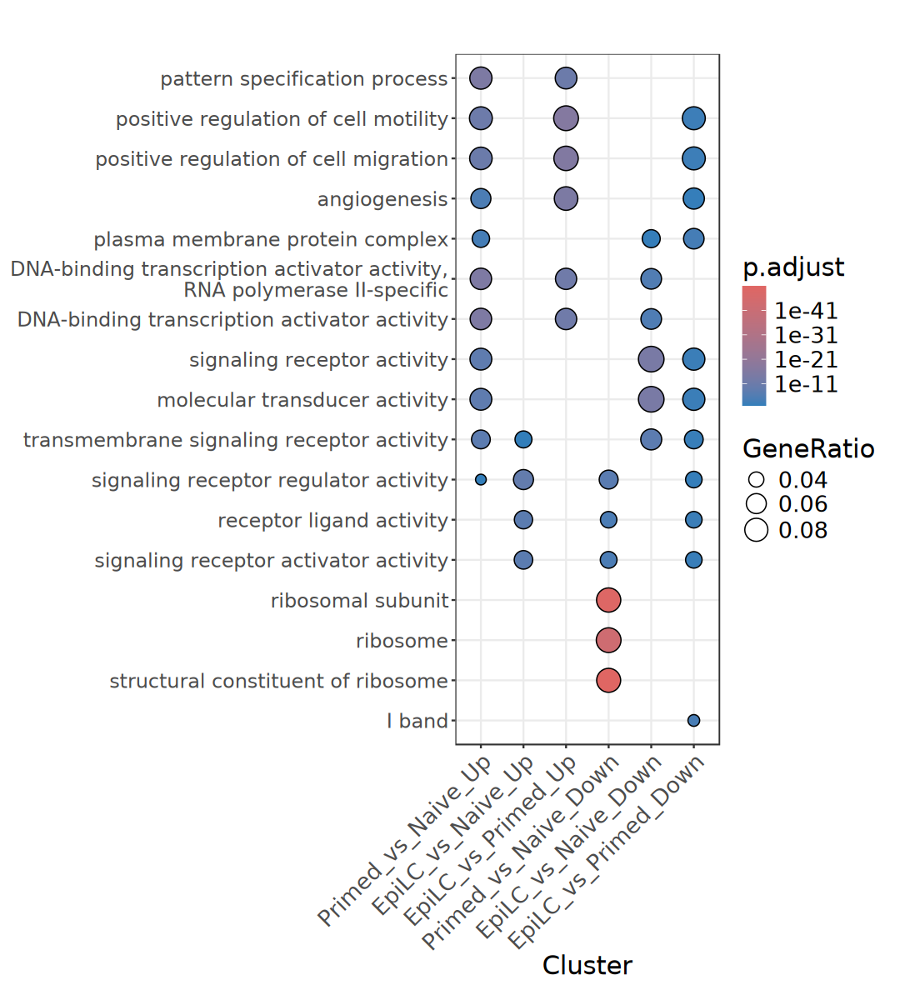

In [151]:
options(repr.plot.width = 9, repr.plot.height = 10)

dotplot(ego_compare, showCategory = 3, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [152]:
deg_types <- c("Up", "Down")

genes_list <- crossing(comp = contrast_labels, deg = deg_types) |>
    pmap(~ deg_df$ENTREZID[deg_df$result == .y & deg_df$contrast == .x]) |>
    set_names(paste(
        contrast_labels, rep(deg_types, each = length(contrast_labels)), 
        sep = "_")) |>
    lapply(unique)

In [153]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(deg_df$ENTREZID), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [154]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,Primed_vs_Naive_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04512,ECM-receptor interaction,23/709,63/5973,0.3650794,3.075626,6.077861,3.288280e-07,0.0001068691,0.0000938025,23
2,Primed_vs_Naive_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04518,Integrin signaling,34/709,122/5973,0.2786885,2.347823,5.519793,1.001373e-06,0.0001627231,0.0001428274,34
3,Primed_vs_Naive_Up,Organismal Systems,Digestive system,mmu04974,Protein digestion and absorption,21/709,62/5973,0.3387097,2.853474,5.383651,4.348763e-06,0.0004711160,0.0004135140,21
4,Primed_vs_Naive_Up,Cellular Processes,Cellular community - eukaryotes,mmu04510,Focal adhesion,40/709,173/5973,0.2312139,1.947871,4.642836,1.861277e-05,0.0015122874,0.0013273843,40
5,Primed_vs_Naive_Up,Organismal Systems,Immune system,mmu04610,Complement and coagulation cascades,13/709,33/5973,0.3939394,3.318759,4.901674,4.921881e-05,0.0031992224,0.0028080624,13
6,Primed_vs_Naive_Up,Environmental Information Processing,Signal transduction,mmu04020,Calcium signaling pathway,37/709,164/5973,0.2256098,1.900659,4.291969,6.703807e-05,0.0033859321,0.0029719436,37


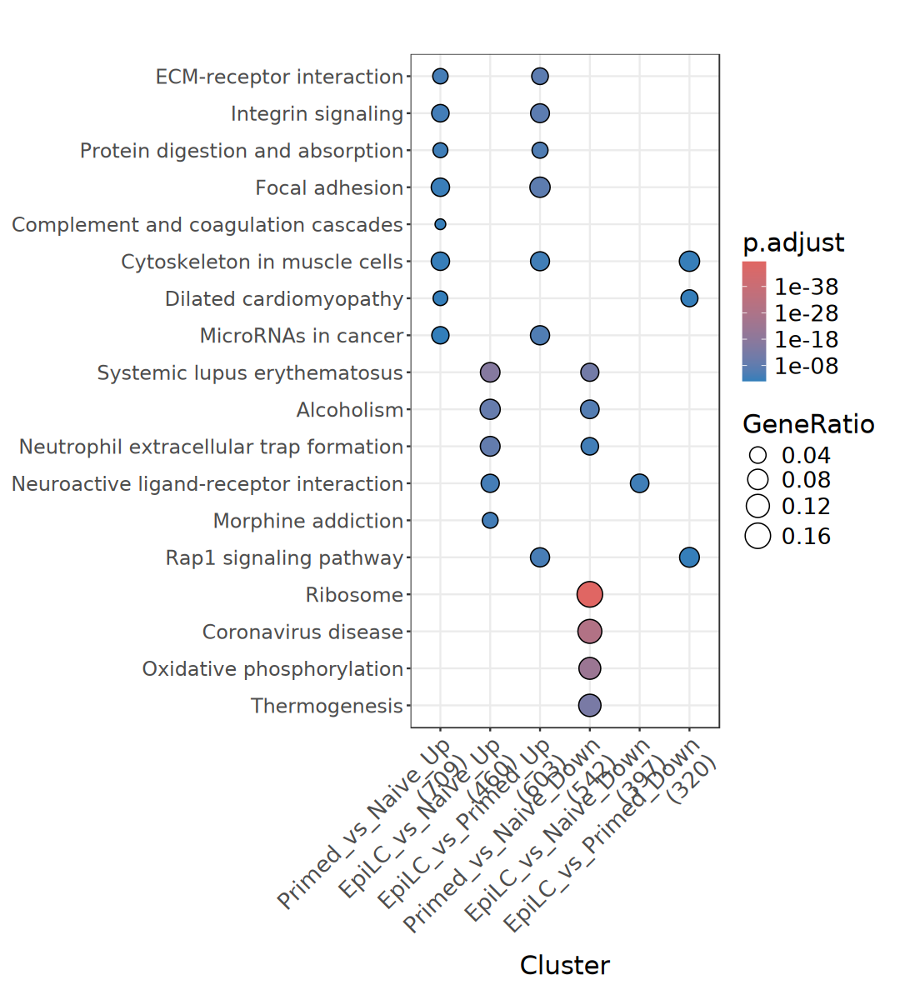

In [155]:
options(repr.plot.width = 9, repr.plot.height = 10)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

### Part 2

In [156]:
gene_map <- bitr(
    rowData(dds)$symbol, OrgDb = org.Mm.eg.db, fromType = "SYMBOL", 
    toType = c("ENTREZID"), drop = FALSE)

'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(rowData(dds)$symbol, OrgDb = org.Mm.eg.db, fromType = "SYMBOL", :
“4% of input gene IDs are fail to map...”


In [157]:
membership_df <- cl_mfuzz$membership |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    pivot_longer(cols = -gene_id, names_to = "cluster", values_to = "membership")

In [158]:
cluster_df <- cl_mfuzz$cluster |> 
    data.frame(cluster = _) |>
    mutate(cluster = as.character(cluster)) |>
    rownames_to_column(var = "gene_id") |>
    left_join(membership_df, by = c("gene_id", "cluster")) |>
    filter(membership > 0.6) |>
    left_join(
        rowData(dds) |> as.data.frame() |> 
        dplyr::select(symbol, type) |>
        rownames_to_column("gene_id"), 
        by = "gene_id") |>
    left_join(gene_map, by = c("symbol" = "SYMBOL"))

table(cluster_df$cluster)
head(cluster_df)


   1    2    3    4    5    6 
 900  643 1141 2235 1632  672 

,gene_id,cluster,membership,symbol,type,ENTREZID
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,ENSMUSG00000068270,1,0.7045570,Shroom4,protein_coding,208431
2,ENSMUSG00000062393,1,0.9982239,Dgkk,protein_coding,331374
3,ENSMUSG00000004317,4,0.9874273,Clcn5,protein_coding,12728
4,ENSMUSG00000046269,4,0.9999987,Usp27x,protein_coding,54651
5,ENSMUSG00000063018,6,0.9999805,2010204K13Rik,lncRNA,68355
6,ENSMUSG00000031143,2,0.8780495,Ccdc22,protein_coding,54638


In [159]:
# membership_df <- cl_tcseq@membership |> 
#     as.data.frame() |> 
#     rownames_to_column(var = "gene_id") |> 
#     pivot_longer(cols = -gene_id, names_to = "cluster", values_to = "membership")

# cluster_df <- cl_tcseq@cluster |> 
#     data.frame(cluster = _) |>
#     mutate(cluster = as.character(cluster)) |>
#     rownames_to_column(var = "gene_id") |>
#     left_join(membership_df, by = c("gene_id", "cluster")) |>
#     filter(membership > 0.6) |>
#     left_join(
#         rowData(dds) |> as.data.frame() |> 
#         dplyr::select(symbol, type) |>
#         rownames_to_column("gene_id"), 
#         by = "gene_id") |>
#     left_join(gene_map, by = c("gene_id" = "ENSEMBL"))

# table(cluster_df$cluster)

In [160]:
gene_list <- split(cluster_df$symbol, cluster_df$cluster)

In [161]:
ego_cluster_compare <- compareCluster(
    geneCluster = gene_list, fun = enrichGO,
    universe = rowData(dds)$symbol, 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [162]:
ego_cluster_compare |> dplyr::select(-geneID) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,1,BP,GO:0061982,meiosis I cell cycle process,24/826,125/12765,0.1920000,2.967167,5.813292,1.277273e-06,6.059383e-03,5.720838e-03,24
2,2,BP,GO:0140236,translation at presynapse,39/556,46/12765,0.8478261,19.464928,26.772615,9.148894e-47,3.134411e-43,3.111587e-43,39
3,2,BP,GO:0140241,translation at synapse,39/556,47/12765,0.8297872,19.050781,26.456126,5.161998e-46,5.895001e-43,5.852075e-43,39
4,2,BP,GO:0140242,translation at postsynapse,39/556,47/12765,0.8297872,19.050781,26.456126,5.161998e-46,5.895001e-43,5.852075e-43,39
5,2,BP,GO:0002181,cytoplasmic translation,68/556,194/12765,0.3505155,8.047356,21.107311,8.108159e-44,6.944639e-41,6.894069e-41,68
6,2,BP,GO:0006119,oxidative phosphorylation,45/556,122/12765,0.3688525,8.468348,17.687651,2.555593e-30,1.751092e-27,1.738341e-27,45


In [163]:
gene_list <- split(cluster_df$ENTREZID, cluster_df$cluster)

In [ ]:
ekegg_cluster_compare <- compareCluster(
    geneCluster = gene_list, fun = enrichKEGG, 
    universe = unique(gene_map$ENTREZID), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [165]:
ekegg_cluster_compare |> dplyr::select(-geneID) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,Primed_vs_Naive_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04512,ECM-receptor interaction,23/709,63/5821,0.3650794,2.997358,5.935805,5.230696e-07,0.0001699976,0.0001503137,23
2,Primed_vs_Naive_Up,Environmental Information Processing,Signaling molecules and interaction,mmu04518,Integrin signaling,34/709,122/5821,0.2786885,2.288076,5.354406,1.808823e-06,0.0002939338,0.0002598993,34
3,Primed_vs_Naive_Up,Organismal Systems,Digestive system,mmu04974,Protein digestion and absorption,21/709,62/5821,0.3387097,2.780859,5.249779,6.551567e-06,0.0007097531,0.0006275712,21
4,Primed_vs_Naive_Up,Cellular Processes,Cellular community - eukaryotes,mmu04510,Focal adhesion,40/709,173/5821,0.2312139,1.898302,4.466704,3.389369e-05,0.0027538621,0.0024349938,40
5,Primed_vs_Naive_Up,Organismal Systems,Immune system,mmu04610,Complement and coagulation cascades,13/709,33/5821,0.3939394,3.234304,4.793184,6.463441e-05,0.0042012368,0.0037147778,13
6,Primed_vs_Naive_Up,Environmental Information Processing,Signal transduction,mmu04020,Calcium signaling pathway,37/709,163/5821,0.2269939,1.863655,4.164777,1.006696e-04,0.0054529366,0.0048215440,37


### Clustered Heatmap

In [166]:
norm_mat <- log2(tpm + 1)

#### 1). Heatmap-ggplot2

In [167]:
plot_df <- norm_mat |> t() |> scale() |> t() |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    pivot_longer(cols = -gene_id, names_to = "sample", values_to = "expression") |>
    right_join(cluster_df, by = "gene_id") |>
    mutate(
        sample = factor(sample, levels = colnames(dds)), 
        cluster = as.factor(cluster)) |>
    arrange(cluster, membership, sample, expression)

head(plot_df)

gene_id,sample,expression,cluster,membership,symbol,type,ENTREZID
<chr>,<fct>,<dbl>,<fct>,<dbl>,<chr>,<chr>,<chr>
ENSMUSG00000056493,Naive_rep1,-0.4143134,1,0.6001077,Foxk1,protein_coding,17425
ENSMUSG00000056493,Naive_rep2,-0.5586788,1,0.6001077,Foxk1,protein_coding,17425
ENSMUSG00000056493,Naive_rep3,-0.3644899,1,0.6001077,Foxk1,protein_coding,17425
ENSMUSG00000056493,Primed_rep1,1.2177035,1,0.6001077,Foxk1,protein_coding,17425
ENSMUSG00000056493,Primed_rep2,1.1957126,1,0.6001077,Foxk1,protein_coding,17425
ENSMUSG00000056493,Primed_rep3,1.4975881,1,0.6001077,Foxk1,protein_coding,17425


In [168]:
line_plot <- ggplot(plot_df, aes(x = sample, y = expression)) +
    geom_path(
        aes(group = gene_id, color = membership),
        linewidth = 0.5, alpha = 0.5) +
    scale_color_distiller(
        palette = "RdYlBu", limits = c(0.6, 1), 
        breaks = seq(0.6, 1, 0.2)) +
    scale_y_continuous(breaks = c(-2, 0, 2)) + 
    facet_wrap(
        ~ cluster, ncol = 1, strip.position = "left",
        labeller = "label_both") + 
    coord_cartesian(clip = "off") + 
    theme_classic() +
    theme(
        panel.border = element_rect(color = "grey", fill = NA, linewidth = 1),
        strip.text = element_text(size = 16),
        strip.background = element_rect(fill = brewer.pal(6, "Set3"), colour = NA),
        legend.title = element_text(size = 18, vjust = 1),
        legend.text = element_text(size = 16),
        legend.position = "top", 
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank())

In [169]:
heatmap_plot <- ggplot(plot_df, aes(x = sample, y = gene_id)) +
    geom_tile(aes(fill = expression)) +
    scale_fill_distiller(palette = "RdYlBu", breaks = c(-2, 0, 2)) +
    facet_wrap(~ cluster, ncol = 1, scales = "free_y") + 
    theme_void() +
    theme(
        panel.border = element_rect(color = "grey", fill = NA, linewidth = 1),
        strip.text = element_blank(),
        legend.title = element_text(size = 18, vjust = 1),
        legend.text = element_text(size = 16),
        legend.position = "top", 
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_blank(),
        axis.ticks.y = element_blank())

In [170]:
strip_plot <- colData(dds) |> as.data.frame() |> 
    rownames_to_column("sample") |>
    mutate(sample = factor(sample, levels = colnames(dds))) |>
    ggplot(aes(x = sample, y = 1)) +
        geom_tile(aes(color = Stage, fill = Stage), width = 1, height = 1) +
        scale_x_discrete(expand = c(0, 0)) +
        scale_color_brewer(palette = "Set3") +
        scale_fill_brewer(palette = "Set3") +
        theme_void() +
        theme(
            legend.title = element_text(size = 18, vjust = 1),
            legend.text = element_text(size = 16))

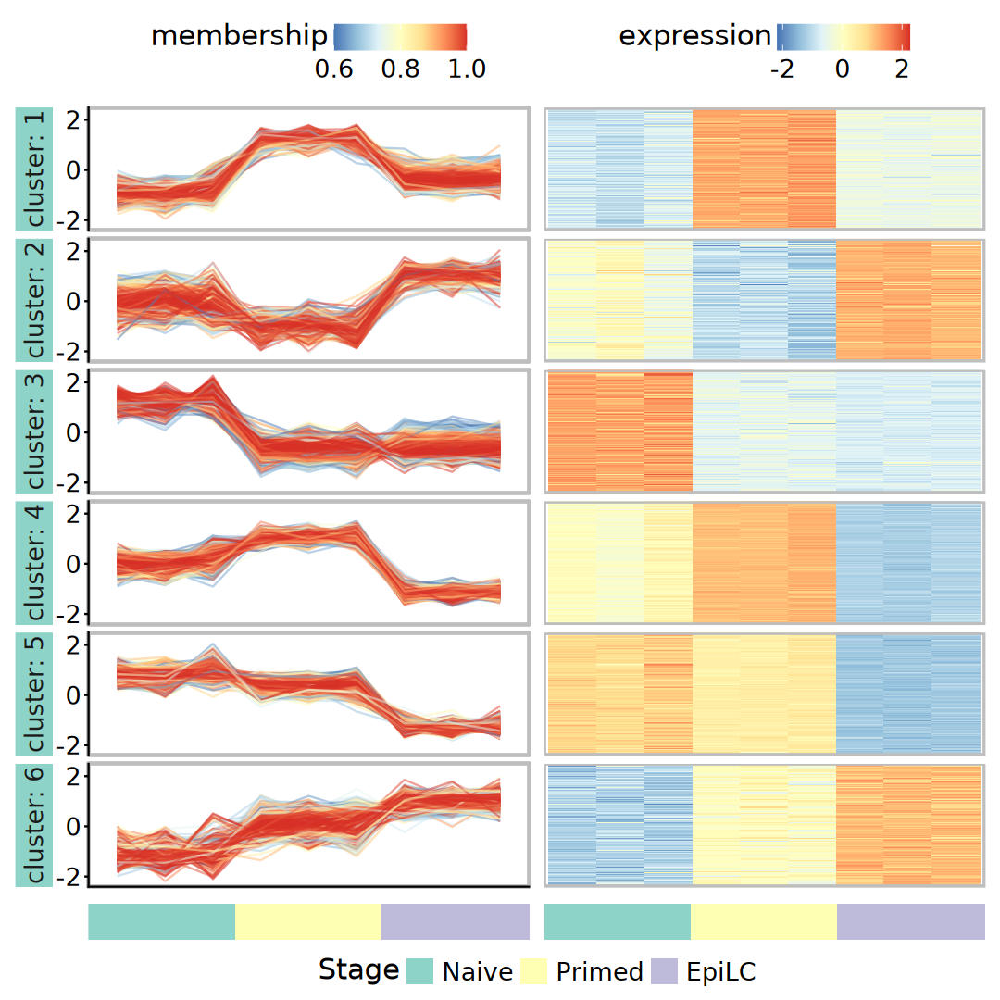

In [171]:
options(repr.plot.width = 9, repr.plot.height = 9)

(line_plot + heatmap_plot) / 
    (strip_plot + strip_plot + plot_layout(guides = "collect") & 
    theme(legend.position = "bottom")) + 
    plot_layout(heights = c(1, 0.05)) & 
    theme(strip.placement = "outside", plot.margin = margin(5, 5, 5, 5))

In [172]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")),
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    summarise(GO_term = paste(GO_term, collapse = "\n")) |>
    left_join(
        plot_df |> group_by(cluster) |> 
            summarise(y_pos = mean(as.numeric(factor(gene_id)))), 
        by = c("Cluster" = "cluster"))
    
head(go_annotations)

Cluster,GO_term,y_pos
<fct>,<chr>,<dbl>
1,meiosis I cell cycle process (BP),450.5
2,translation at presynapse (BP) translation at synapse (BP) translation at postsynapse (BP) cytoplasmic translation (BP) oxidative phosphorylation (BP),322.0
3,lipid catabolic process (BP) fatty acid metabolic process (BP) small molecule catabolic process (BP) amide metabolic process (BP) carbohydrate metabolic process (BP),571.0
4,epigenetic regulation of gene expression (BP) positive regulation of cell cycle process (BP) response to transforming growth factor beta (BP) regulation of cytoskeleton organization (BP) mRNA destabilization (BP),1118.0
5,positive regulation of cell motility (BP) axon development (BP) positive regulation of cell migration (BP) regulation of neuron projection development (BP) axonogenesis (BP),816.5
6,organellar large ribosomal subunit (CC) mitochondrial large ribosomal subunit (CC) mitochondrial protein-containing complex (CC) organellar ribosome (CC) mitochondrial ribosome (CC),336.5


In [173]:
annotation_plot <- ggplot(go_annotations, aes(x = 0, y = y_pos)) +
    geom_text(
        aes(color = GO_term, label = GO_term), 
        hjust = 0, size = 4, show.legend = FALSE) +
    facet_wrap(~ Cluster, ncol = 1, scales = "free_y") +
    scale_color_brewer(palette = "Dark2") + 
    xlim(c(0, 1)) +
    theme_test() + 
    theme(
        strip.text = element_blank(),
        axis.title = element_blank(),
        axis.text = element_blank(),
        axis.ticks = element_blank())

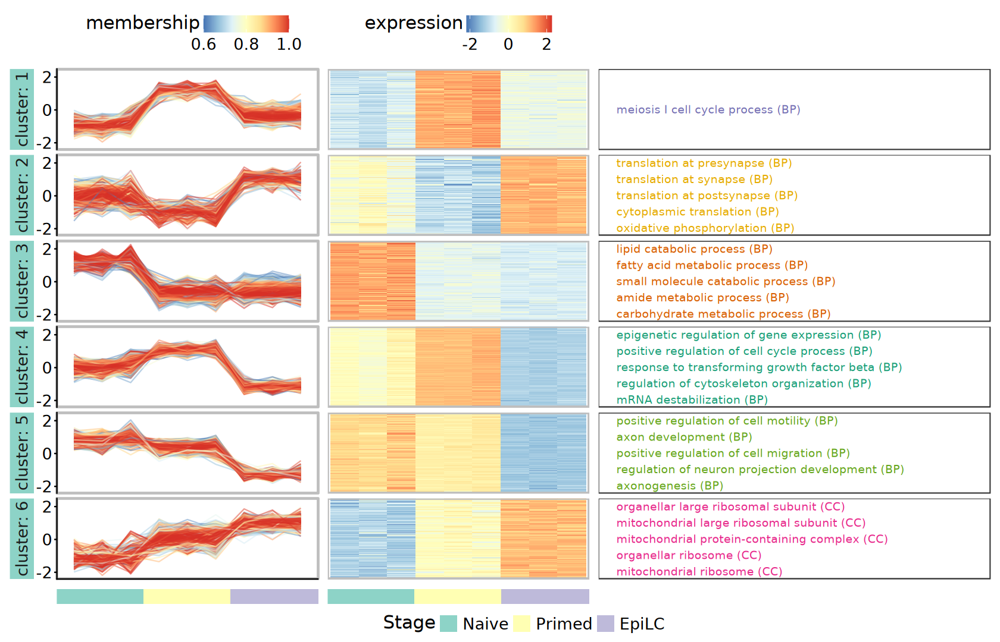

In [174]:
options(repr.plot.width = 14, repr.plot.height = 9)
top_row <- line_plot + heatmap_plot + annotation_plot +
    plot_layout(widths = c(2, 2, 3))
bottom_row <- strip_plot + strip_plot + plot_spacer() +
    plot_layout(widths = c(2, 2, 3), guides = "collect") & 
    theme(legend.position = "bottom")

top_row / bottom_row + 
    plot_layout(heights = c(1, 0.03)) &
    theme(
        plot.margin = margin(5, 5, 5, 5),
        strip.placement = "outside")

#### 2). ComplexHeatmap

In [175]:
cluster_df <- cluster_df |>
    mutate(cluster = factor(paste0("cluster", cluster)))

In [176]:
ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Stage, Replicate)

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Stage)),
    levels(dds$Stage))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Stage = group_colors, 
        Replicate = replicate_colors))

In [177]:
ar <- cluster_df |> 
    dplyr::select(gene_id, Cluster = cluster) |>
    column_to_rownames("gene_id") |>
    arrange(Cluster)

cluster_colors <- setNames(
    scales::brewer_pal(palette = "Set3")(nlevels(ar$Cluster)),
    levels(ar$Cluster))

left_anno <- rowAnnotation(
    df = ar, col = list(Cluster = cluster_colors),
    show_legend = FALSE)

In [178]:
heatmap_dat <- norm_mat[rownames(ar), ]

heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

In [179]:
gene_labels <- cluster_df |>
    filter(type == "protein_coding") |>
    group_by(cluster) |>
    slice_max(order_by = membership, n = 5, with_ties = FALSE) |>
    ungroup()

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$symbol[
    match(rownames(heatmap_dat)[mark_rows], 
    gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)),
    width = unit(2.5, "cm"))

In [180]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)

lg_group <- Legend(
    title = "Stage", labels = levels(dds$Stage))

lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))

lg_cluster <- Legend(
    labels = levels(ar$Cluster), title = "Cluster", 
    legend_gp = gpar(fill = cluster_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [181]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE, 
        use_raster = TRUE)

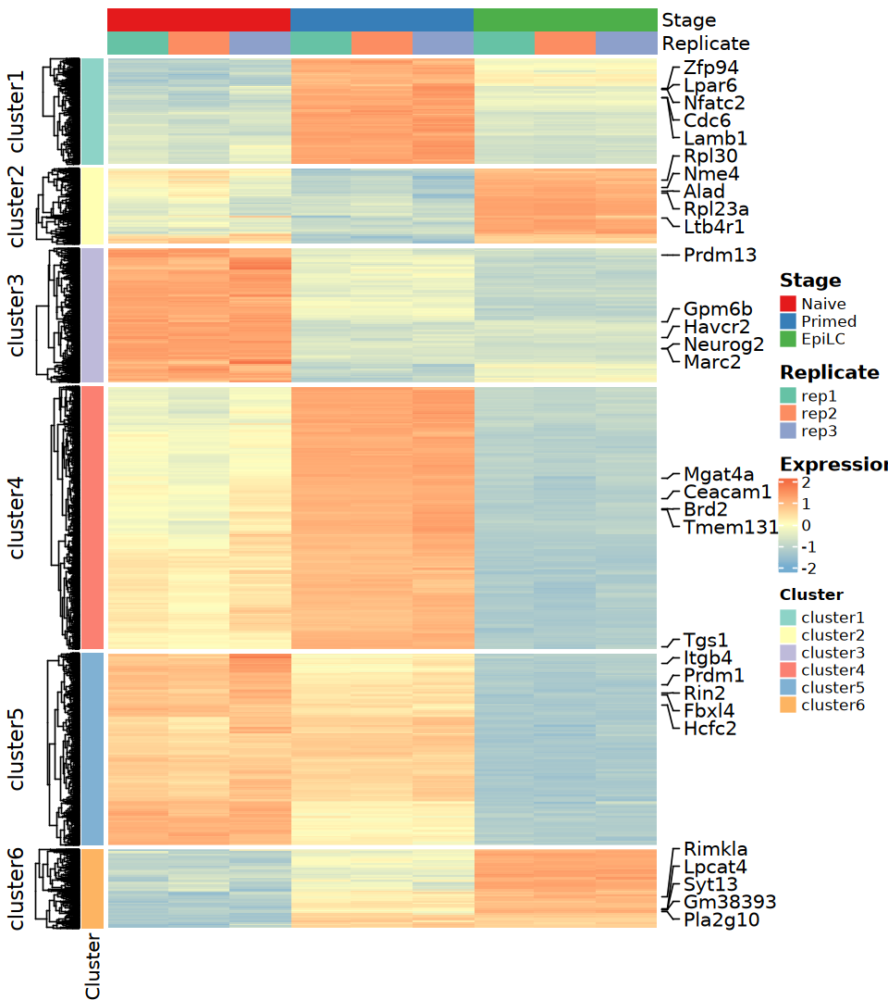

In [182]:
options(repr.plot.width = 8, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [183]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")),
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    summarise(GO_term = paste(GO_term, collapse = "\n")) |>
    mutate(Cluster = factor(paste0("cluster", Cluster)))

head(go_annotations)

Cluster,GO_term
<fct>,<chr>
cluster1,meiosis I cell cycle process (BP)
cluster2,translation at presynapse (BP) translation at synapse (BP) translation at postsynapse (BP) cytoplasmic translation (BP) oxidative phosphorylation (BP)
cluster3,lipid catabolic process (BP) fatty acid metabolic process (BP) small molecule catabolic process (BP) amide metabolic process (BP) carbohydrate metabolic process (BP)
cluster4,epigenetic regulation of gene expression (BP) positive regulation of cell cycle process (BP) response to transforming growth factor beta (BP) regulation of cytoskeleton organization (BP) mRNA destabilization (BP)
cluster5,positive regulation of cell motility (BP) axon development (BP) positive regulation of cell migration (BP) regulation of neuron projection development (BP) axonogenesis (BP)
cluster6,organellar large ribosomal subunit (CC) mitochondrial large ribosomal subunit (CC) mitochondrial protein-containing complex (CC) organellar ribosome (CC) mitochondrial ribosome (CC)


In [184]:
go_term_data_list <- split(go_annotations$GO_term, go_annotations$Cluster)

In [185]:
right_annotation <- rowAnnotation(
    textbox = anno_textbox(
        ar$Cluster, go_term_data_list,
        background_gp = gpar(fill = "#ffffff"),
        gp = gpar(fontsize = 12), max_width = unit(10, "cm"), 
        add_new_line = TRUE, round_corners = TRUE), 
    width = unit(12, "cm"))
# word_wrap = TRUE, 

In [186]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

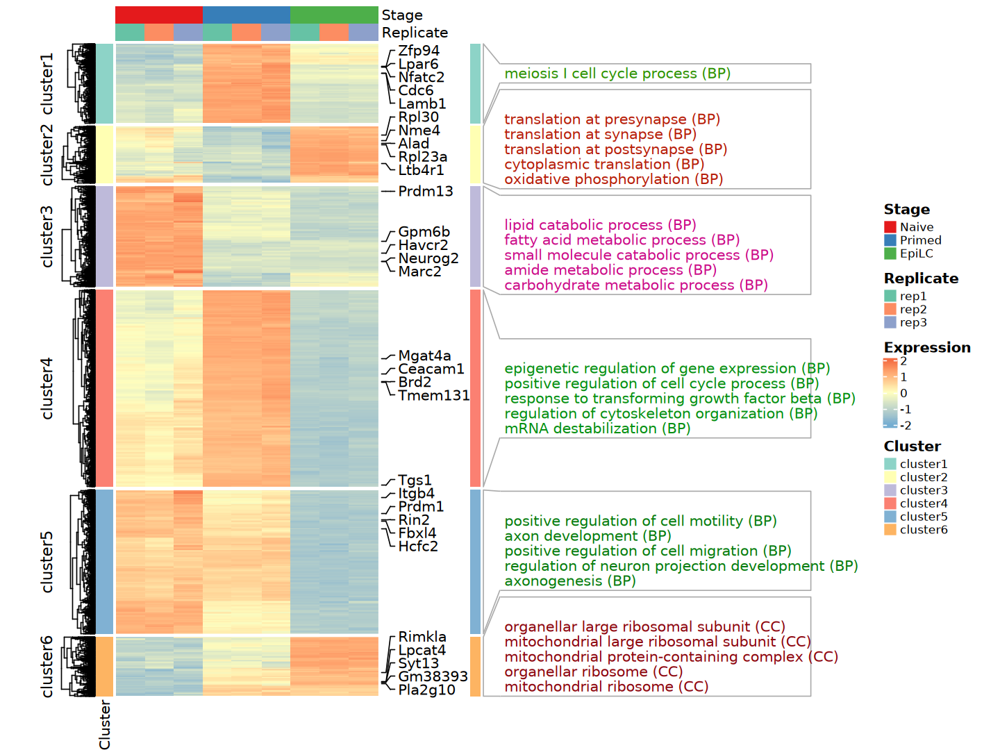

In [187]:
options(repr.plot.width = 12, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    # annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [188]:
s_heatmap_dat <- heatmap_dat |> t() |> scale() |> t()

In [189]:
panel_fun_boxplot <- function(s_heatmap_dat, group_colors = NULL) {
    function(index, nm) {
        tmp <- s_heatmap_dat[index, , drop = FALSE]
        pos <- seq(0, 1, length.out = ncol(tmp))
        rng <- range(tmp, na.rm = TRUE)
        norm <- (tmp - rng[1]) / (rng[2] - rng[1])
        fills <- if (is.null(group_colors)) "grey70" else group_colors |>
            rep(each = 3)
        bw <- min(0.1, 0.9 / max(1, ncol(tmp)))

        grid::pushViewport(grid::viewport(xscale = c(-0.1, 1.1), yscale = c(0, 1.2)))
        grid::grid.rect()                         
        for (i in seq_len(ncol(norm))) {
            grid.boxplot(
                norm[, i], pos = pos[i],
                direction = "vertical",
                box_width = bw, outline = FALSE,
                gp = grid::gpar(col = "grey50", fill = fills[i]))
        }
        grid::grid.lines(
            x = pos, y = apply(norm, 2, median, na.rm = TRUE),
            gp = grid::gpar(col = "red", lwd = 0.5))
        grid::grid.text(
            paste0("Genes: ", nrow(tmp)), 0.5, 0.9, 
            gp = grid::gpar(fontsize = 6))
        grid::popViewport()
    }
}

In [190]:
panel_fun <- panel_fun_boxplot(s_heatmap_dat, group_colors)
left_anno2 <- rowAnnotation(
    boxplot = anno_link(
        align_to = factor(ar$Cluster), which = "row",
        panel_fun = panel_fun, side = "left",
        size = grid::unit(3, "cm"),
        width = grid::unit(6, "cm"),
        gap = grid::unit(0.25, "cm"),
        link_gp = grid::gpar(fill = "grey90", col = NA)))

In [191]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno2, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        show_row_dend = FALSE,
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

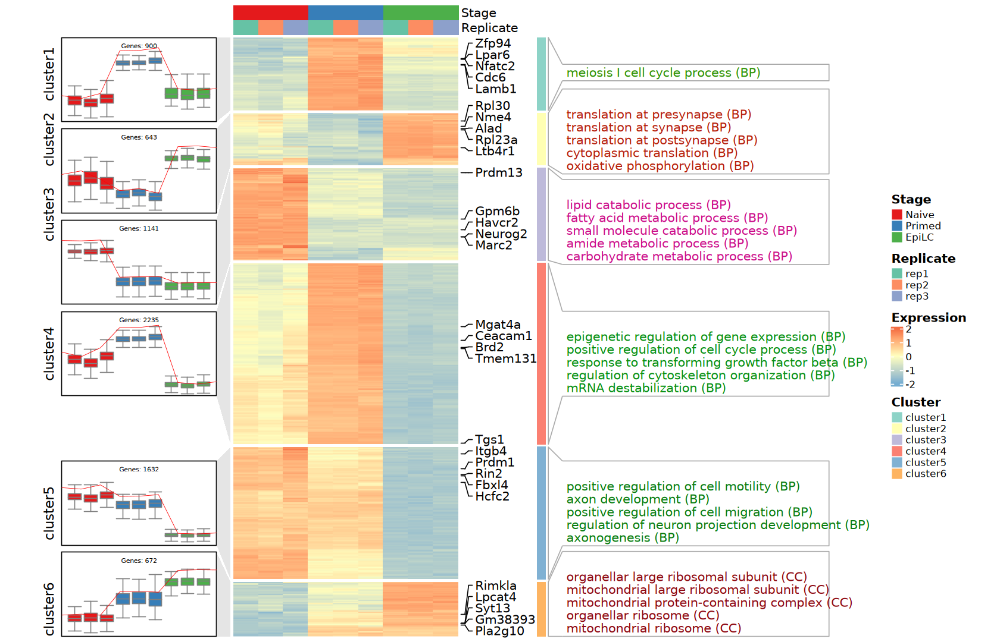

In [192]:
options(repr.plot.width = 14, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    # annotation_legend_list = list(lg_cluster), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

In [193]:
panel_fun_pathplot <- function(
    s_heatmap_dat, cluster_df, palette = c("blue","white","red")) {
    
    function(index, nm) {
        tmp <- s_heatmap_dat[index, , drop = FALSE]
        # pos <- scales::rescale(1:ncol(tmp), to = c(0, 1))
        pos <- seq(0, 1, length.out = ncol(tmp))
        rng <- range(tmp, na.rm = TRUE)
        norm <- (tmp - rng[1]) / (rng[2] - rng[1])
        
        mem <- cluster_df$membership[match(rownames(tmp), cluster_df$gene_id)]
        mem_idx <- round(mem * 100)
        line_colors <- grDevices::colorRampPalette(palette)(100)
        line_cols <- line_colors[mem_idx]

        pushViewport(grid::viewport(xscale = c(-0.1, 1.1), yscale = c(0, 1.2)))
        grid.rect()
        for (i in seq_len(nrow(norm))) {
            grid.lines(
                x = pos, y = norm[i, ], 
                gp = gpar(col = line_cols[i], lwd = 0.5))
        }
        grid.text(paste0("Genes: ", nrow(tmp)), 0.5, 0.9, gp = grid::gpar(fontsize = 6))
        popViewport()
    }
}

In [194]:
palette = c(
    "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
    "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
    "#F46D43", "#D53E4F", "#9E0142")

In [195]:
panel_fun <- panel_fun_pathplot(s_heatmap_dat, cluster_df, palette)
left_anno3 <- rowAnnotation(
    boxplot = anno_link(
        align_to = factor(ar$Cluster), which = "row",
        panel_fun = panel_fun, side = "left",
        size = grid::unit(3, "cm"),
        width = grid::unit(6, "cm"),
        gap = grid::unit(0.25, "cm"),
        link_gp = grid::gpar(fill = "grey90", col = NA)))

In [196]:
line_colors <- circlize::colorRamp2(
    breaks = seq(0, 1, length.out = length(palette)), 
    colors = palette)

lg_line <- Legend(
    title = "Membership", col_fun = line_colors, 
    at = c(0, 0.5, 1), labels = c("0", "0.5", "1"))

In [197]:
combined_leg <- list(lg_heatmap, lg_group, lg_replicate, lg_line) |>
    packLegend(direction = "vertical")

In [198]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col, 
        row_split = factor(ar$Cluster),
        top_annotation = top_anno,
        left_annotation = left_anno3, 
        right_annotation = right_anno,
        cluster_row_slices = FALSE, cluster_columns = FALSE,
        show_row_names = FALSE, show_column_names = FALSE, 
        show_row_dend = FALSE,
        width = unit(8, "cm"), use_raster = TRUE) +
    Heatmap(
        ar$Cluster, name = "Cluster", 
        col = cluster_colors,
        show_column_names = FALSE,
        right_annotation = right_annotation,
        width = unit(0.3, "cm"))

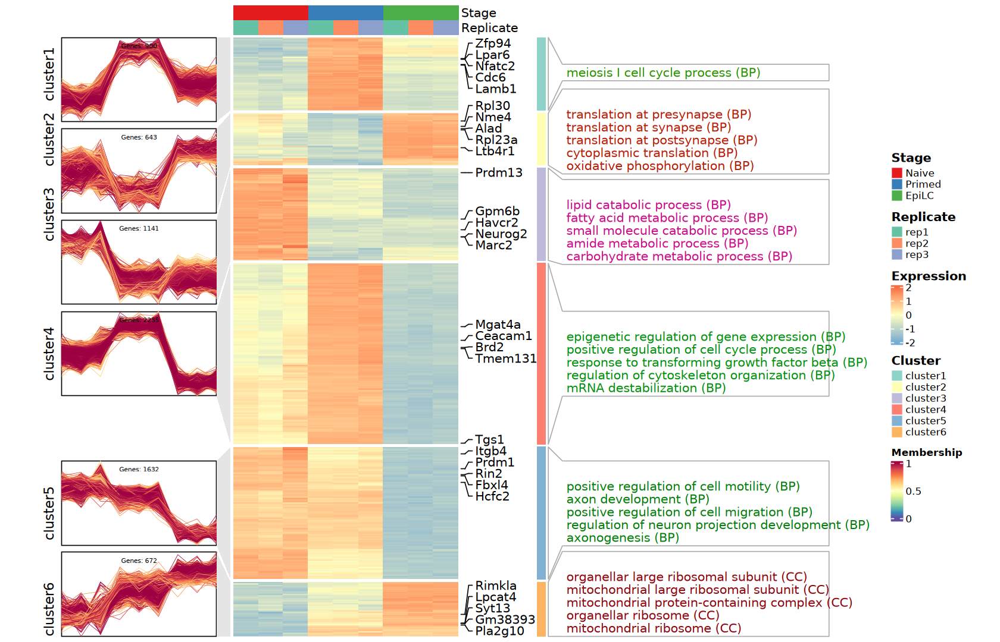

In [199]:
options(repr.plot.width = 14, repr.plot.height = 9)
draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_line),
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 2), "mm"))

#### 3). [ClusterGVis](https://github.com/junjunlab/ClusterGVis)

> - To enhance clustering and visualization of time-series gene expression data from RNA-Seq experiments.

In [200]:
suppressPackageStartupMessages(library(ClusterGVis))

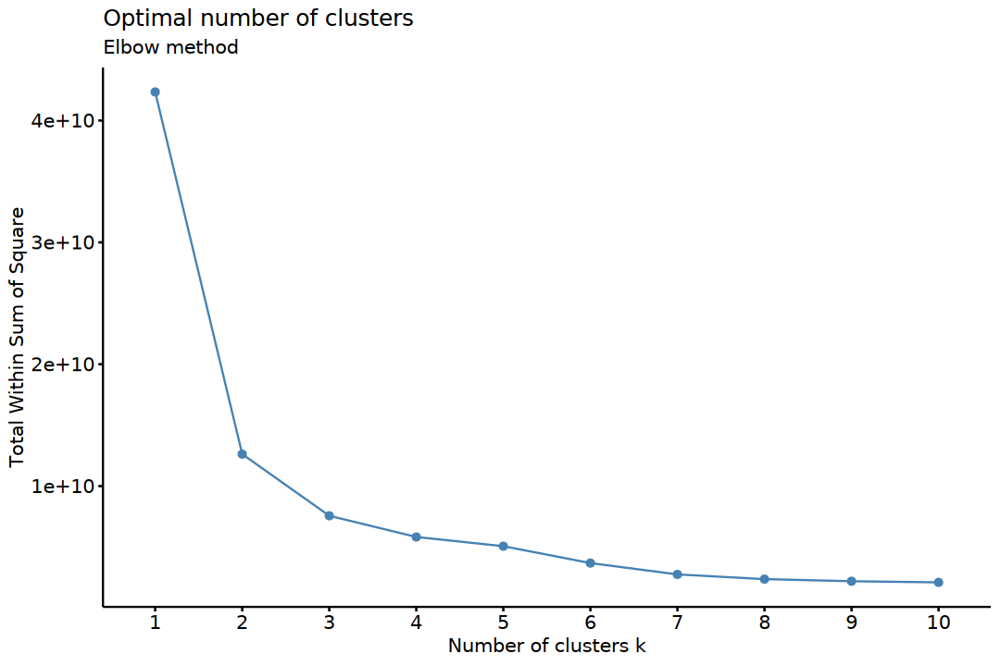

In [201]:
options(repr.plot.width = 9, repr.plot.height = 6)
getClusters(tpm)
# ~ 2 min

In [202]:
cl <- clusterData(tpm, cluster.method = "mfuzz", cluster.num = 6)

[1] "0 genes excluded.\n"


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ClusterGVis package.
  Please report the issue at <https://github.com/junjunlab/ClusterGVis/issues>.”


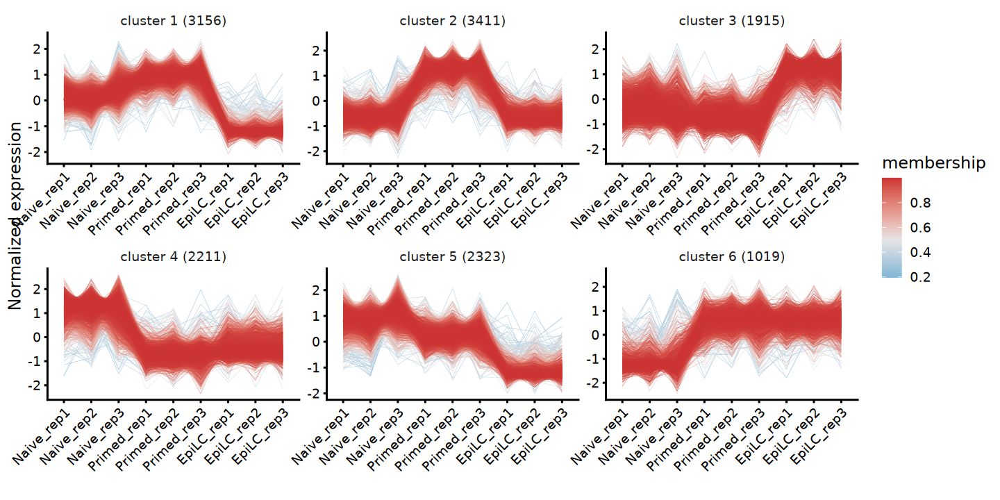

In [203]:
options(repr.plot.width = 12, repr.plot.height = 6)
visCluster(object = cl, plot.type = "line", ncol = 3)

In [204]:
markGenes = rownames(tpm)[sample(1:nrow(tpm), 30, replace = F)]

In [205]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    dplyr::select(Cluster, ONTOLOGY, ID, Description, p.adjust, Count) |>
    mutate(
        ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC")), 
        GO_term = paste0(Description, " (", ONTOLOGY, ")")) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, p.adjust, .by_group = TRUE) |>
    slice_head(n = 5) |>
    ungroup() |>
    mutate(Cluster = factor(paste0("C", Cluster))) |>
    dplyr::select(id = Cluster, term = GO_term)

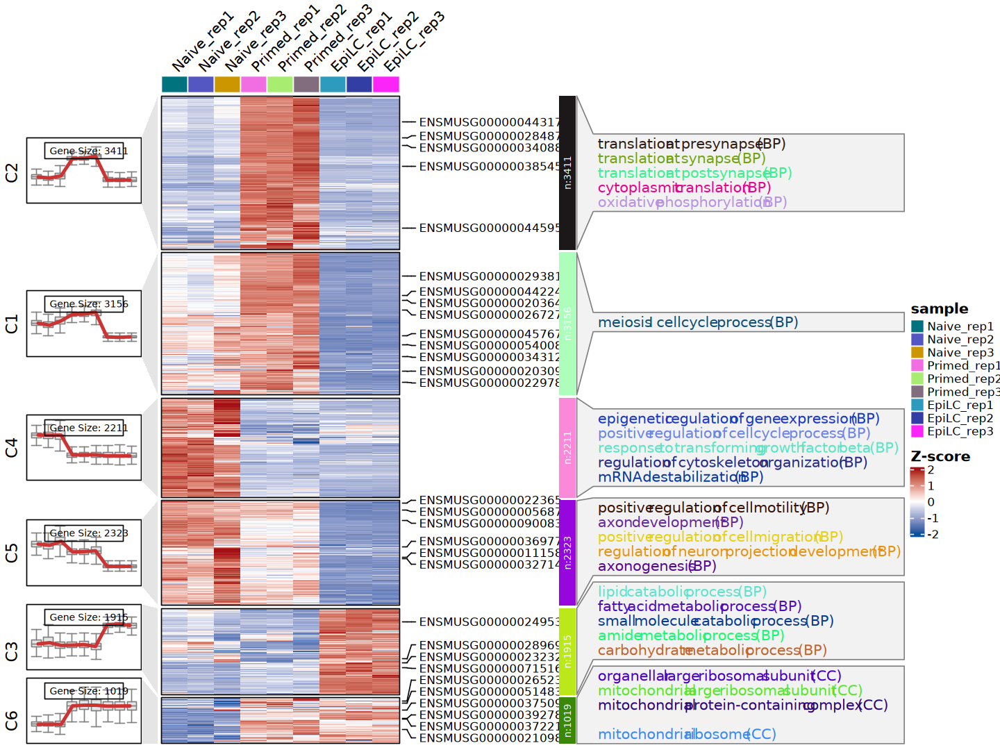

In [206]:
options(repr.plot.width = 12, repr.plot.height = 9)
visCluster(
    object = cl, 
    # HeatmapAnnotation = top_anno,
    plot.type = "both", line.side = "left", add.box = TRUE,
    markGenes = markGenes, genes.gp = c('italic', 10, "black"),
    annoTerm.data = go_annotations, 
    column_names_rot = 45, show_row_dend = FALSE)

In [207]:
go_annotations <- ego_cluster_compare |> as.data.frame() |> 
    mutate(ONTOLOGY = factor(ONTOLOGY, levels = c("BP", "MF", "CC"))) |>
    group_by(Cluster) |> 
    arrange(ONTOLOGY, qvalue, .by_group = TRUE) |>
    slice_head(n = 5) |>
    ungroup() |>
    dplyr::select(group = Cluster, Description, qvalue, ratio = Count) |>
    mutate(group = factor(paste0("C", group)))

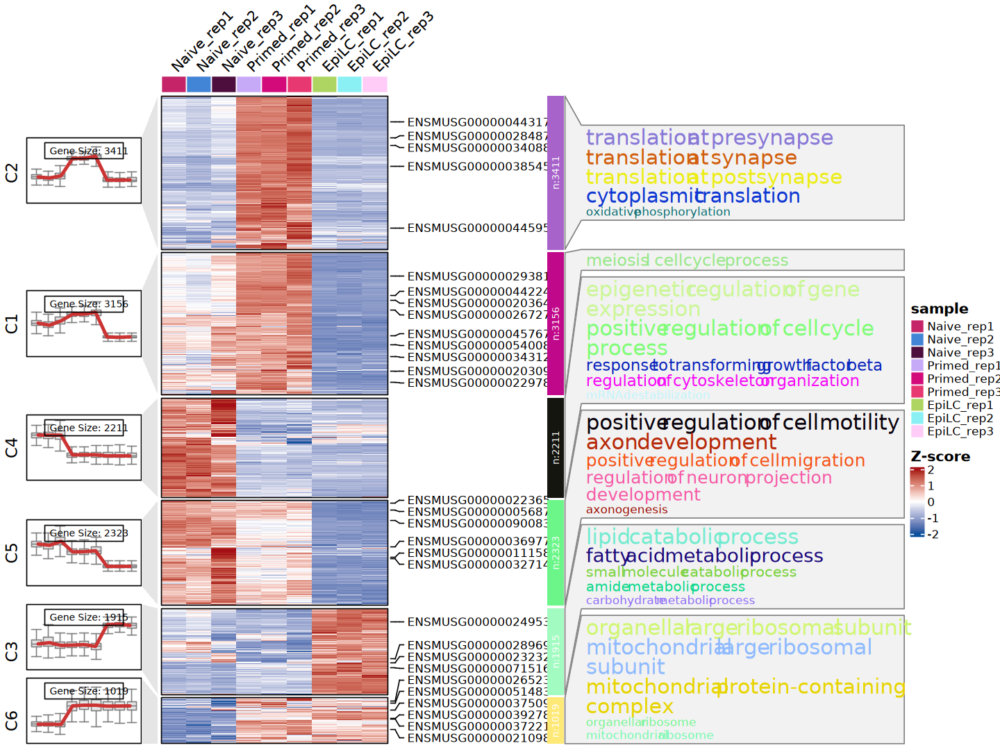

In [208]:
options(repr.plot.width = 12, repr.plot.height = 9)
visCluster(
    object = cl, 
    # HeatmapAnnotation = top_anno,
    plot.type = "both", line.side = "left", add.box = TRUE,
    markGenes = markGenes, genes.gp = c('italic', 10, "black"),
    annoTerm.data = go_annotations, go.size = "pval",
    # go.col = rep(ggsci::pal_d3()(6), each = 5), 
    column_names_rot = 45, show_row_dend = FALSE)

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)